# Transcriptomic panel call confidence

**Question:** How well do full-transcriptome calls and clusters survive restriction to the BLYM777 panel, and how well does the full Lymph2Cx reconstruction reproduce reported assay calls in external NanoString data?

The performance benchmarks use external cohorts: **Schmitz, Morin (BC Cancer), Li**, plus **Chapuy as separate microarray sensitivity**, and **GSE178394** for NanoString calibration.

The two endpoints are distinct: panel restriction tests **feature retention**, while GSE178394 tests agreement with **reported Lymph2Cx assay calls**. Neither directly establishes RNA-seq/NanoString measurement equivalence. Full-input predictions are not biological ground truth. “Confidence” below is empirical recall/precision, not interchangeable posterior probabilities across classifiers.

In [1]:
NOTEBOOK_NAME = 'transcriptomic_panel_call_confidence'
from pathlib import Path
import sys, os, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dlbcl/public_panel_confidence.py').is_file())
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLBACKEND', 'Agg')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Image
from dlbcl.public_panel_confidence import (
    load_public_adata, table, require_source, SOURCES,
    metrics_from_counts, plot_bars, plot_transitions, label_colors, plot_feature_coverage,
    plot_subtype_feature_coverage, subtype_coverage_table)
mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["font.family"] = "DejaVu Sans"
# This section needs feature definitions only; benchmark data are loaded later.
from dlbcl.panel_feature_requirements import (
    load_requirements, genomic_design_coverage, transcriptomic_design_coverage)
requirements = load_requirements(ROOT / 'data/public/panel_feature_requirements.json')
LABEL_COLORS = label_colors(ROOT / 'config/classifier_colors.json')
OUT = ROOT / 'figures' / NOTEBOOK_NAME
OUT.mkdir(parents=True, exist_ok=True)
def show_save(fig, name):
    for extension in ['png', 'svg']:
        fig.savefig(OUT / f'{name}.{extension}', dpi=160)
    plt.close(fig)
    display(Image(filename=str(OUT / f'{name}.png')))
print('Loaded declared panel targets and author-model feature requirements.')


Loaded declared panel targets and author-model feature requirements.


## Transcriptomic panel design: requested versus declared features

One cell per classifier shows **All** and the subtype breakdown. Coverage is the intersection of the declared BLYM777 target list with the reference feature requirements. The calculation uses only the accompanying feature-definition JSON; no AnnData, whole-transcriptome dataset or sample expression is needed.

The counts describe **features supported by the panel design**, not observed expression or assay detection. Benchmark matrices and sample-level availability enter only in the performance section below. Shared inputs across subtypes are labelled explicitly.

### LymphoMAP — panel requirement and author-reference selection

Each archetype has two bars. **Upper, filled green:** the declared panel supports the configured 50-gene selection requirement per archetype, 150 overall. **Lower, blue plus grey:** coverage of a single full-reference list, selected once with the authors' implementation and default criteria from the author training reference. The panel-specific list is selected using those same rules restricted to declared BLYM777 genes. Neither selection uses a benchmark/query expression dataset.

This shows design feasibility and original-list overlap. It does not show that every gene is expressed, passes assay QC, or yields a correct classification in a given sample.

The paper explains the selection rule in its Methods:

> From the set of genes shared between the query and training datasets, features are selected based on differential expression analysis using DESeq2.

[Li et al., 2025, LymphoMapR classifier](https://pmc.ncbi.nlm.nih.gov/articles/PMC12417684/)

Thus, the reference selection can be adapted to the available panel genes. The paper uses 50 features per archetype and applies the classifier to NanoString datasets; it does not require retaining a fixed whole-transcriptome top-gene list.

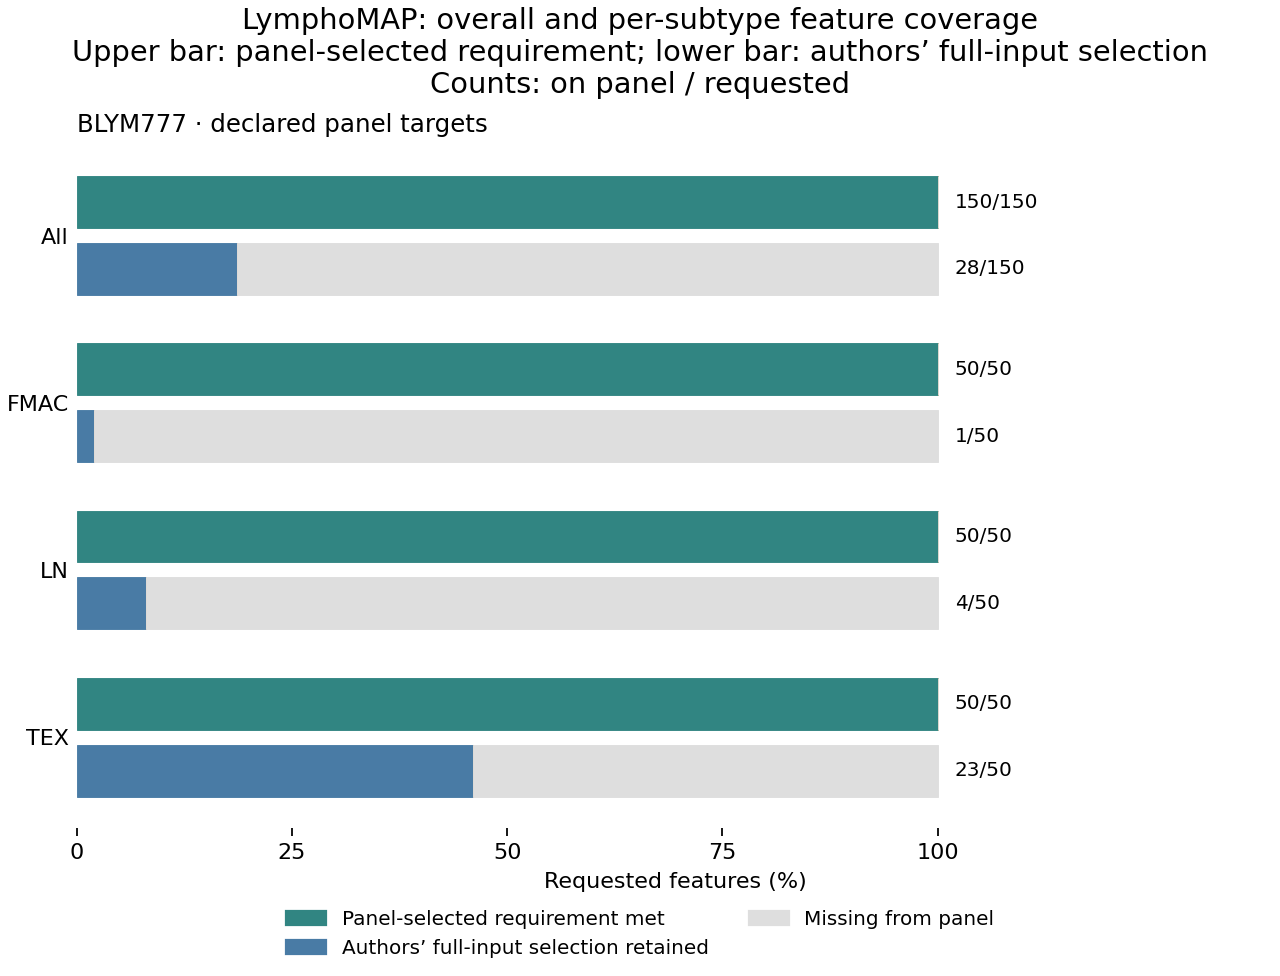

,panel,subtype,feature_basis,Panel coverage,not_on_panel
0,BLYM777,All,Full-reference genes,28/150,122
1,BLYM777,FMAC,Full-reference genes,1/50,49
2,BLYM777,LN,Full-reference genes,4/50,46
3,BLYM777,TEX,Full-reference genes,23/50,27
4,BLYM777,All,Panel-reselected genes,150/150,0
5,BLYM777,FMAC,Panel-reselected genes,50/50,0
6,BLYM777,LN,Panel-reselected genes,50/50,0
7,BLYM777,TEX,Panel-reselected genes,50/50,0


In [2]:
coverage, design_features = transcriptomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('LymphoMAP')]
show_save(plot_subtype_feature_coverage(coverage, 'LymphoMAP', design=True), 'lymphomap_subtype_feature_coverage')
display(subtype_coverage_table(coverage, design=True))
coverage.to_csv(OUT / 'lymphomap_subtype_feature_coverage.csv', index=False)

### EcoTyper — overall and LE1–LE9

The declared BLYM777 targets are compared directly with the authors' recovery-basis gene lists. **All** is their union. Each ecotype uses the union of bases for the cell types contributing its constituent states, according to the author membership table. The basis is shared by states within a cell type; these are not independent ecotype classifiers. No expression matrix or detected-gene filtering enters this calculation.

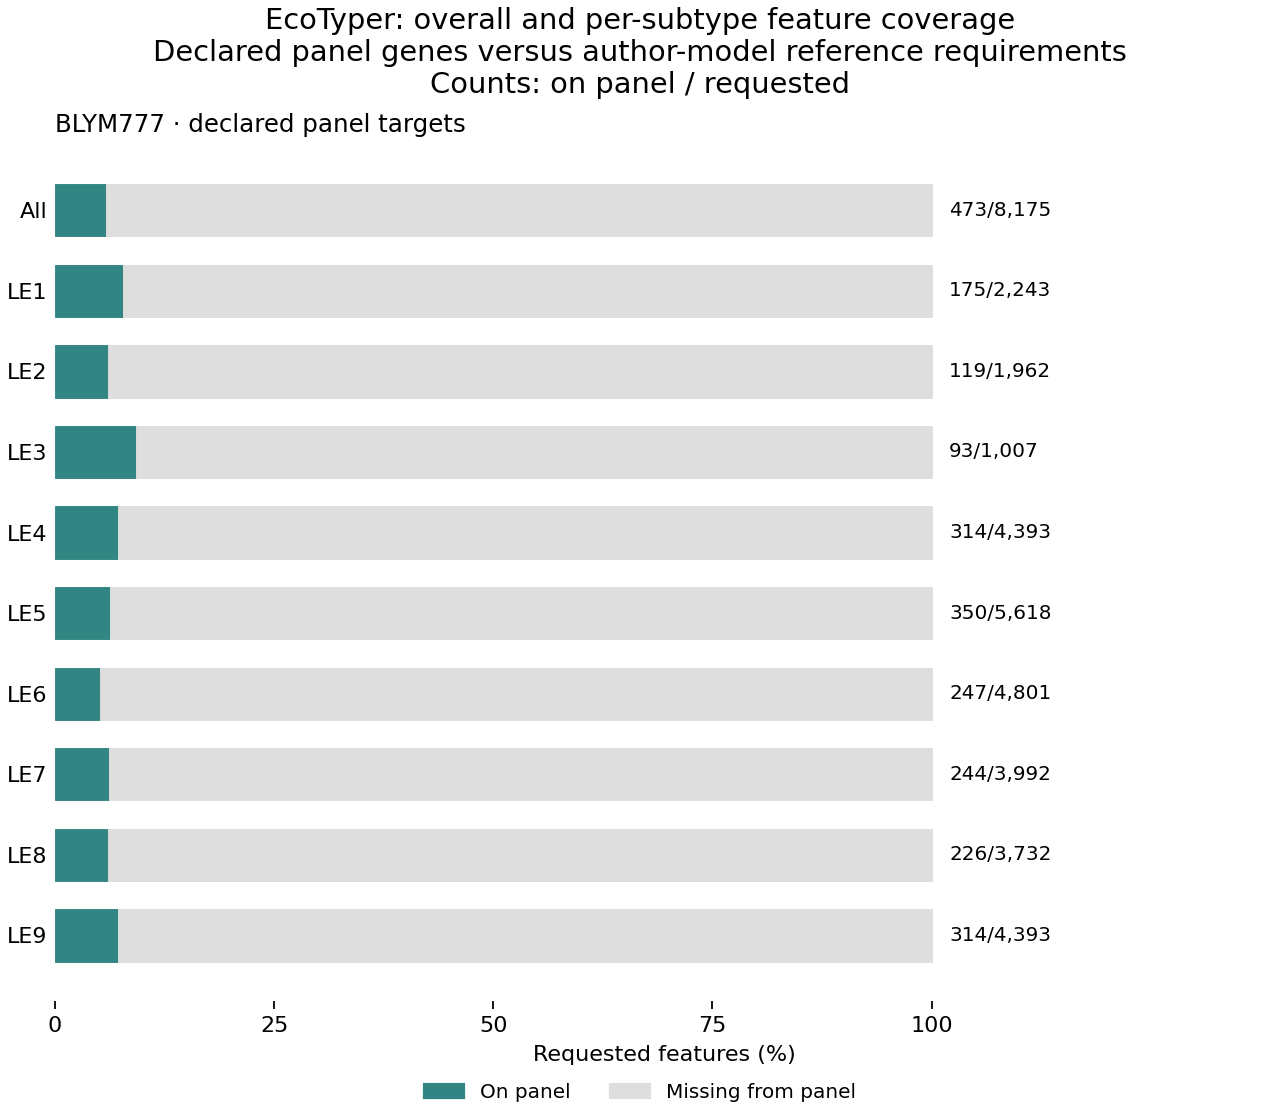

,panel,subtype,feature_basis,Panel coverage,not_on_panel
8,BLYM777,All,Full-reference genes,473/8175,7702
9,BLYM777,LE1,Full-reference genes,175/2243,2068
10,BLYM777,LE2,Full-reference genes,119/1962,1843
11,BLYM777,LE3,Full-reference genes,93/1007,914
12,BLYM777,LE4,Full-reference genes,314/4393,4079
13,BLYM777,LE5,Full-reference genes,350/5618,5268
14,BLYM777,LE6,Full-reference genes,247/4801,4554
15,BLYM777,LE7,Full-reference genes,244/3992,3748
16,BLYM777,LE8,Full-reference genes,226/3732,3506
17,BLYM777,LE9,Full-reference genes,314/4393,4079


In [3]:
coverage, design_features = transcriptomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('EcoTyper')]
show_save(plot_subtype_feature_coverage(coverage, 'EcoTyper', design=True), 'ecotyper_subtype_feature_coverage')
display(subtype_coverage_table(coverage, design=True))
coverage.to_csv(OUT / 'ecotyper_subtype_feature_coverage.csv', index=False)

### Kotlov — the 25 functional inputs

The four LME categories arise from patterns across shared inputs: **22 curated signatures scored by ssGSEA and three pathways scored by PROGENy**. The original study clustered their scores to define the categories. Four repeated gene-coverage bars therefore conceal the useful variation, which lies between these signatures/pathways. [Kotlov et al., Methods](https://pmc.ncbi.nlm.nih.gov/articles/PMC8178179/)

The gene sets below were checked against the authors' GMT file, selected-signature list and PROGENy coefficient table. They are the Kotlov inputs, rather than generic replacement GSEA sets. [Author definitions](https://github.com/BostonGene/LME)

BLYM777 covers **151/205 unique ssGSEA genes (74%)**, compared with **41/300 PROGENy genes (14%)**. Their combined union is **184/494 (37%)**; genes shared between sets are counted once in each union. Angiogenesis, B cells, NK cells and several other signatures are fully covered, whereas PI3K contains only 2/100 panel genes. The three large pathway sets explain much of the lower overall fraction.

This is gene-list coverage, not score fidelity or classification accuracy. ssGSEA also depends on its ranking background, and PROGENy uses unequal gene coefficients. Requested and panel-retained ssGSEA GMT files, per-signature gene lists and the PROGENy coefficients are exported below.

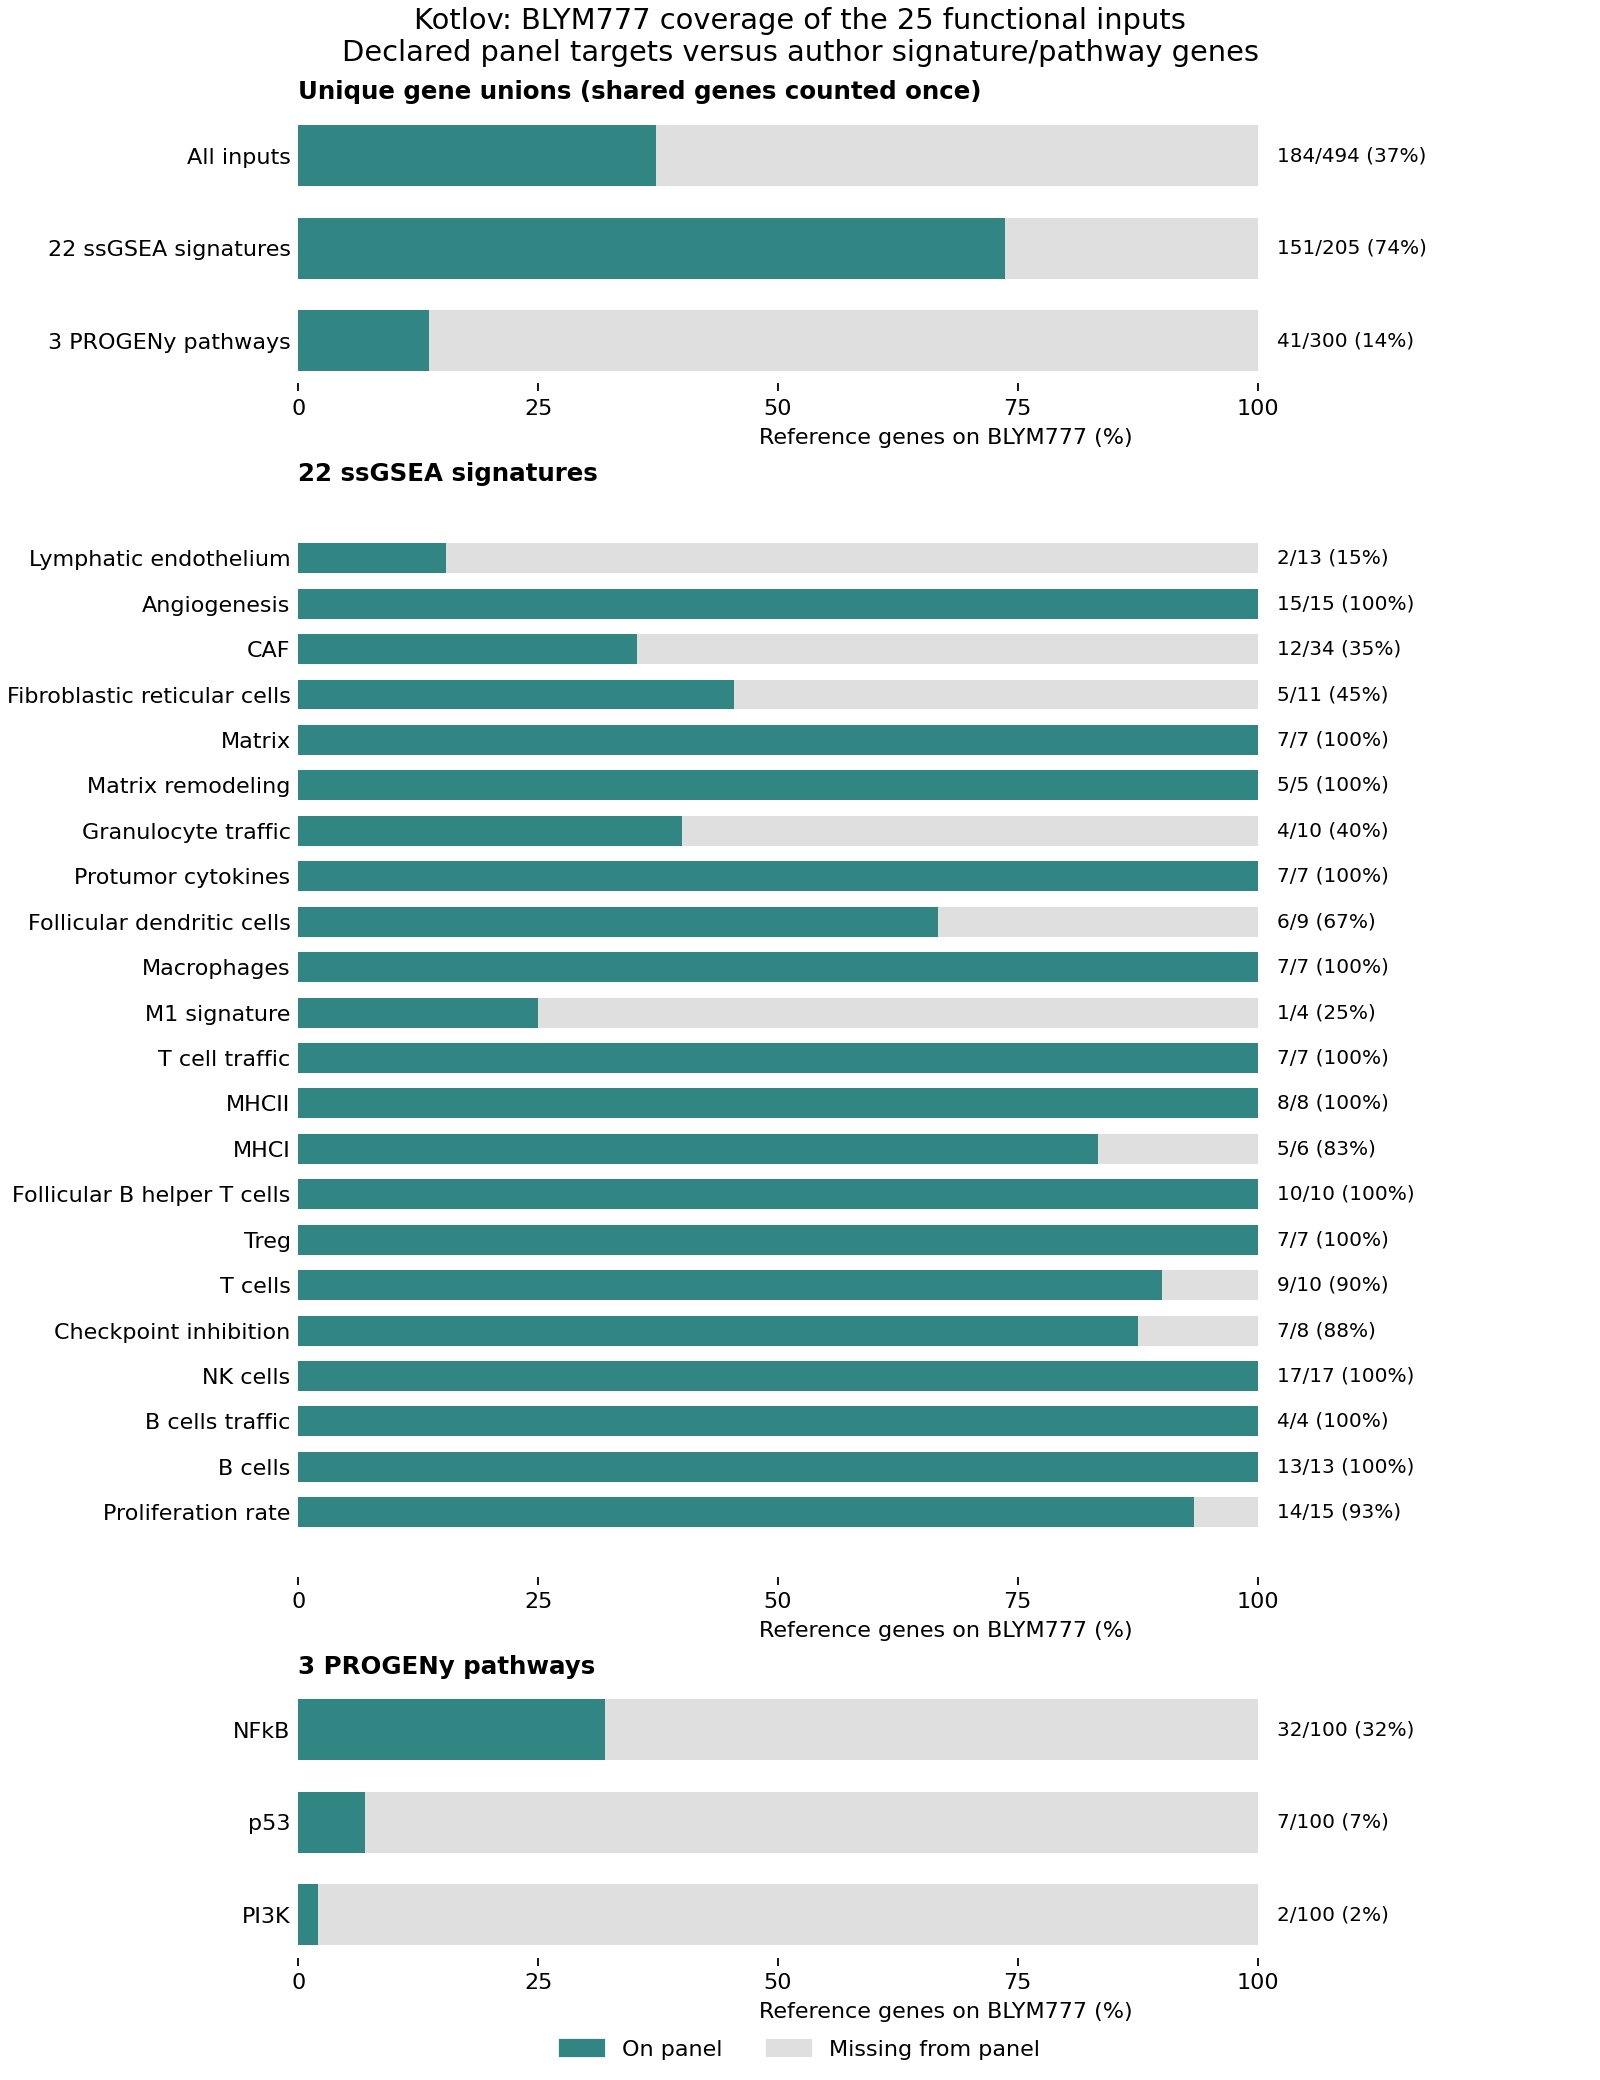

,group,requested,on_panel,missing,coverage_pct
0,All inputs,494,184,310,37.2
1,22 ssGSEA signatures,205,151,54,73.7
2,3 PROGENy pathways,300,41,259,13.7


,signature,method,requested,on_panel,missing,coverage_pct
0,Lymphatic_endothelium,ssGSEA,13,2,11,15.4
1,Angiogenesis,ssGSEA,15,15,0,100.0
2,CAF,ssGSEA,34,12,22,35.3
3,Fibroblastic_reticular_cells,ssGSEA,11,5,6,45.5
4,Matrix,ssGSEA,7,7,0,100.0
5,Matrix_remodeling,ssGSEA,5,5,0,100.0
6,Granulocyte_traffic,ssGSEA,10,4,6,40.0
7,Protumor_cytokines,ssGSEA,7,7,0,100.0
8,Follicular_dendritic_cells,ssGSEA,9,6,3,66.7
9,Macrophages,ssGSEA,7,7,0,100.0


Exported reference/panel ssGSEA GMT files, signature gene lists and PROGENy coefficients.


In [4]:
from dlbcl.panel_feature_requirements import (
    kotlov_signature_coverage, export_kotlov_gene_sets, plot_kotlov_signature_coverage)
kotlov_coverage, kotlov_summary, kotlov_features = kotlov_signature_coverage(requirements)
show_save(plot_kotlov_signature_coverage(kotlov_coverage, kotlov_summary), 'kotlov_signature_feature_coverage')
display(kotlov_summary.round(1))
display(kotlov_coverage.round(1))
export_kotlov_gene_sets(requirements, OUT)
print('Exported reference/panel ssGSEA GMT files, signature gene lists and PROGENy coefficients.')

### Ciavarella — overall and High / Intermediate / Low

All three categories use the same 45-gene signature, and all 45 genes are declared BLYM777 targets. This panel-design result is independent of whether a particular benchmark matrix happens to omit one of those genes.

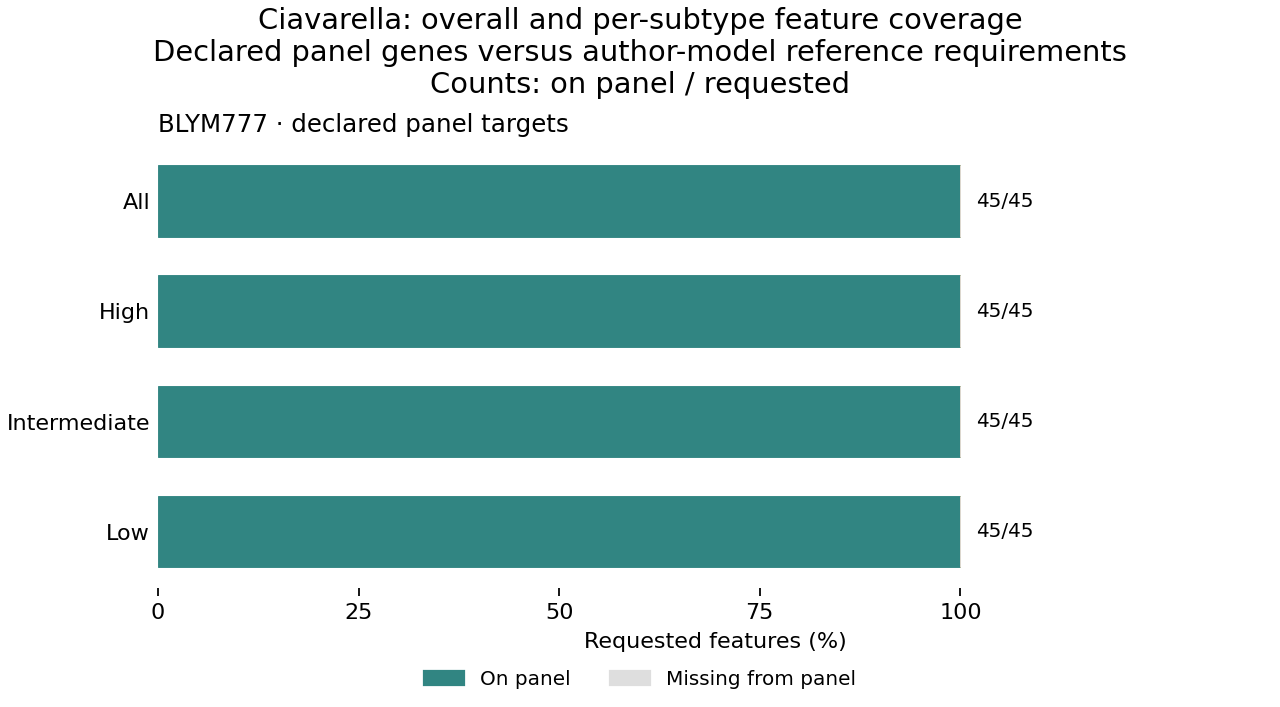

,panel,subtype,feature_basis,Panel coverage,not_on_panel
23,BLYM777,All,Full-reference genes,45/45,0
24,BLYM777,High,Full-reference genes,45/45,0
25,BLYM777,Intermediate,Full-reference genes,45/45,0
26,BLYM777,Low,Full-reference genes,45/45,0


In [5]:
coverage, design_features = transcriptomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('Ciavarella')]
show_save(plot_subtype_feature_coverage(coverage, 'Ciavarella', design=True), 'ciavarella_subtype_feature_coverage')
display(subtype_coverage_table(coverage, design=True))
coverage.to_csv(OUT / 'ciavarella_subtype_feature_coverage.csv', index=False)

### Lymph2Cx — overall and GCB / UNC / ABC

All outcomes use the same 15 predictors and five housekeeping genes. BLYM777 targets all 20, giving 20/20 coverage overall and for each outcome. UNC is an intermediate score range, not a separate signature. Historical gene aliases are harmonized in the reference definitions. Sample-level detection and external-dataset availability are separate from this design calculation.

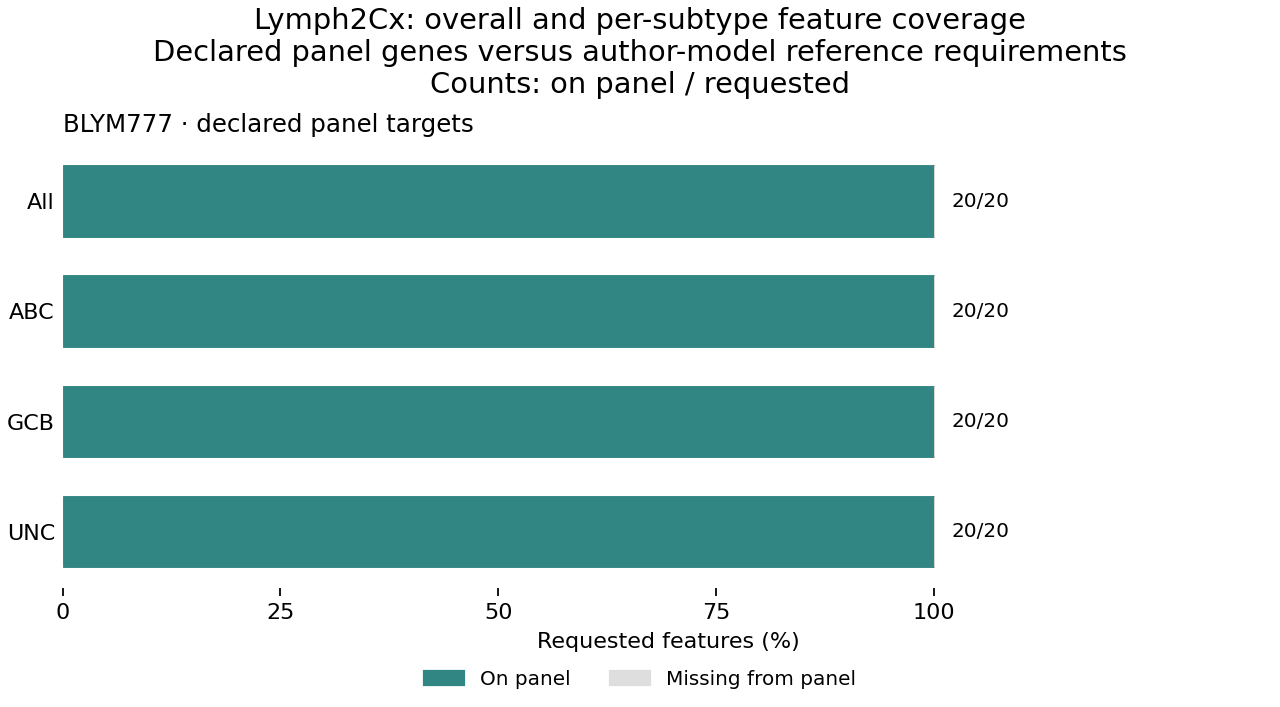

,panel,subtype,feature_basis,Panel coverage,not_on_panel
27,BLYM777,All,Full-reference genes,20/20,0
28,BLYM777,GCB,Full-reference genes,20/20,0
29,BLYM777,UNC,Full-reference genes,20/20,0
30,BLYM777,ABC,Full-reference genes,20/20,0


In [6]:
coverage, design_features = transcriptomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('Lymph2Cx')]
show_save(plot_subtype_feature_coverage(coverage, 'Lymph2Cx', design=True), 'lymph2cx_subtype_feature_coverage')
display(subtype_coverage_table(coverage, design=True))
coverage.to_csv(OUT / 'lymph2cx_subtype_feature_coverage.csv', index=False)

In [7]:
design_coverage, design_features = transcriptomic_design_coverage(requirements)
design_coverage.to_csv(OUT / 'declared_panel_coverage.csv', index=False)
design_features.to_csv(OUT / 'declared_panel_feature_list.csv', index=False)

## External-data performance benchmarks

The panel-design audit above is complete without cohort data. The following cells load external benchmark results to assess call retention, recall/precision and sample-level input availability. Missing genes in an external matrix do not change the declared panel coverage.

## Cohorts, features and native classifier handling

The BLYM777 definition contains **797 measured targets**. Full and panel-restricted runs retain the same expression values and samples; there is no post-masking rescaling. Historical symbols were harmonized, with redundant aliases averaged on the log-expression scale.

Schmitz and Morin use `log2(x+1)` of their supplied linear million-sum matrices. Li's supplied logTPM is retained. Chapuy is a separate microarray analysis with `log2(x+1)` of the supplied positive matrix; its exact upstream preprocessing remains uncertain.

LymphoMapR uses native training-based feature selection and ComBat alignment, 50 requested genes per archetype and posterior cutoff 0 (argmax). EcoTyper uses native bulk recovery, Q < 0.25 and its assigned-state rule; missing reference genes are handled by native code. Ecotype abundance is not a posterior probability. **Schmitz overlaps EcoTyper discovery; Li overlaps LymphoMAP training**, so these are not uniformly independent validation cohorts. Li's 11 controls are excluded from pooled tumor plots; its 142 tumors remain included.

Sources: [LymphoMAP](https://pmc.ncbi.nlm.nih.gov/articles/PMC12417684/), [EcoTyper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9205168/), [Kotlov](https://pmc.ncbi.nlm.nih.gov/articles/PMC8178179/), [Ciavarella](https://pmc.ncbi.nlm.nih.gov/articles/PMC6311951/). Cohort-specific access references appear at the end.

In [8]:
ADATA_PATH = ROOT / 'data/public/panel_call_confidence.public.h5ad'
adata = load_public_adata(ADATA_PATH)

,cohort,samples,canonical_genes,panel_genes_present,input_scale,platform
0,Schmitz,522,24981,786,linear million-sum; log2(x+1),RNA-seq
1,Morin,302,18328,746,linear million-sum; log2(x+1),RNA-seq
2,Li,153,37397,781,log2 expression (retained),RNA-seq
3,Chapuy,135,20362,742,supplied linear microarray expression; log2(x+1),microarray


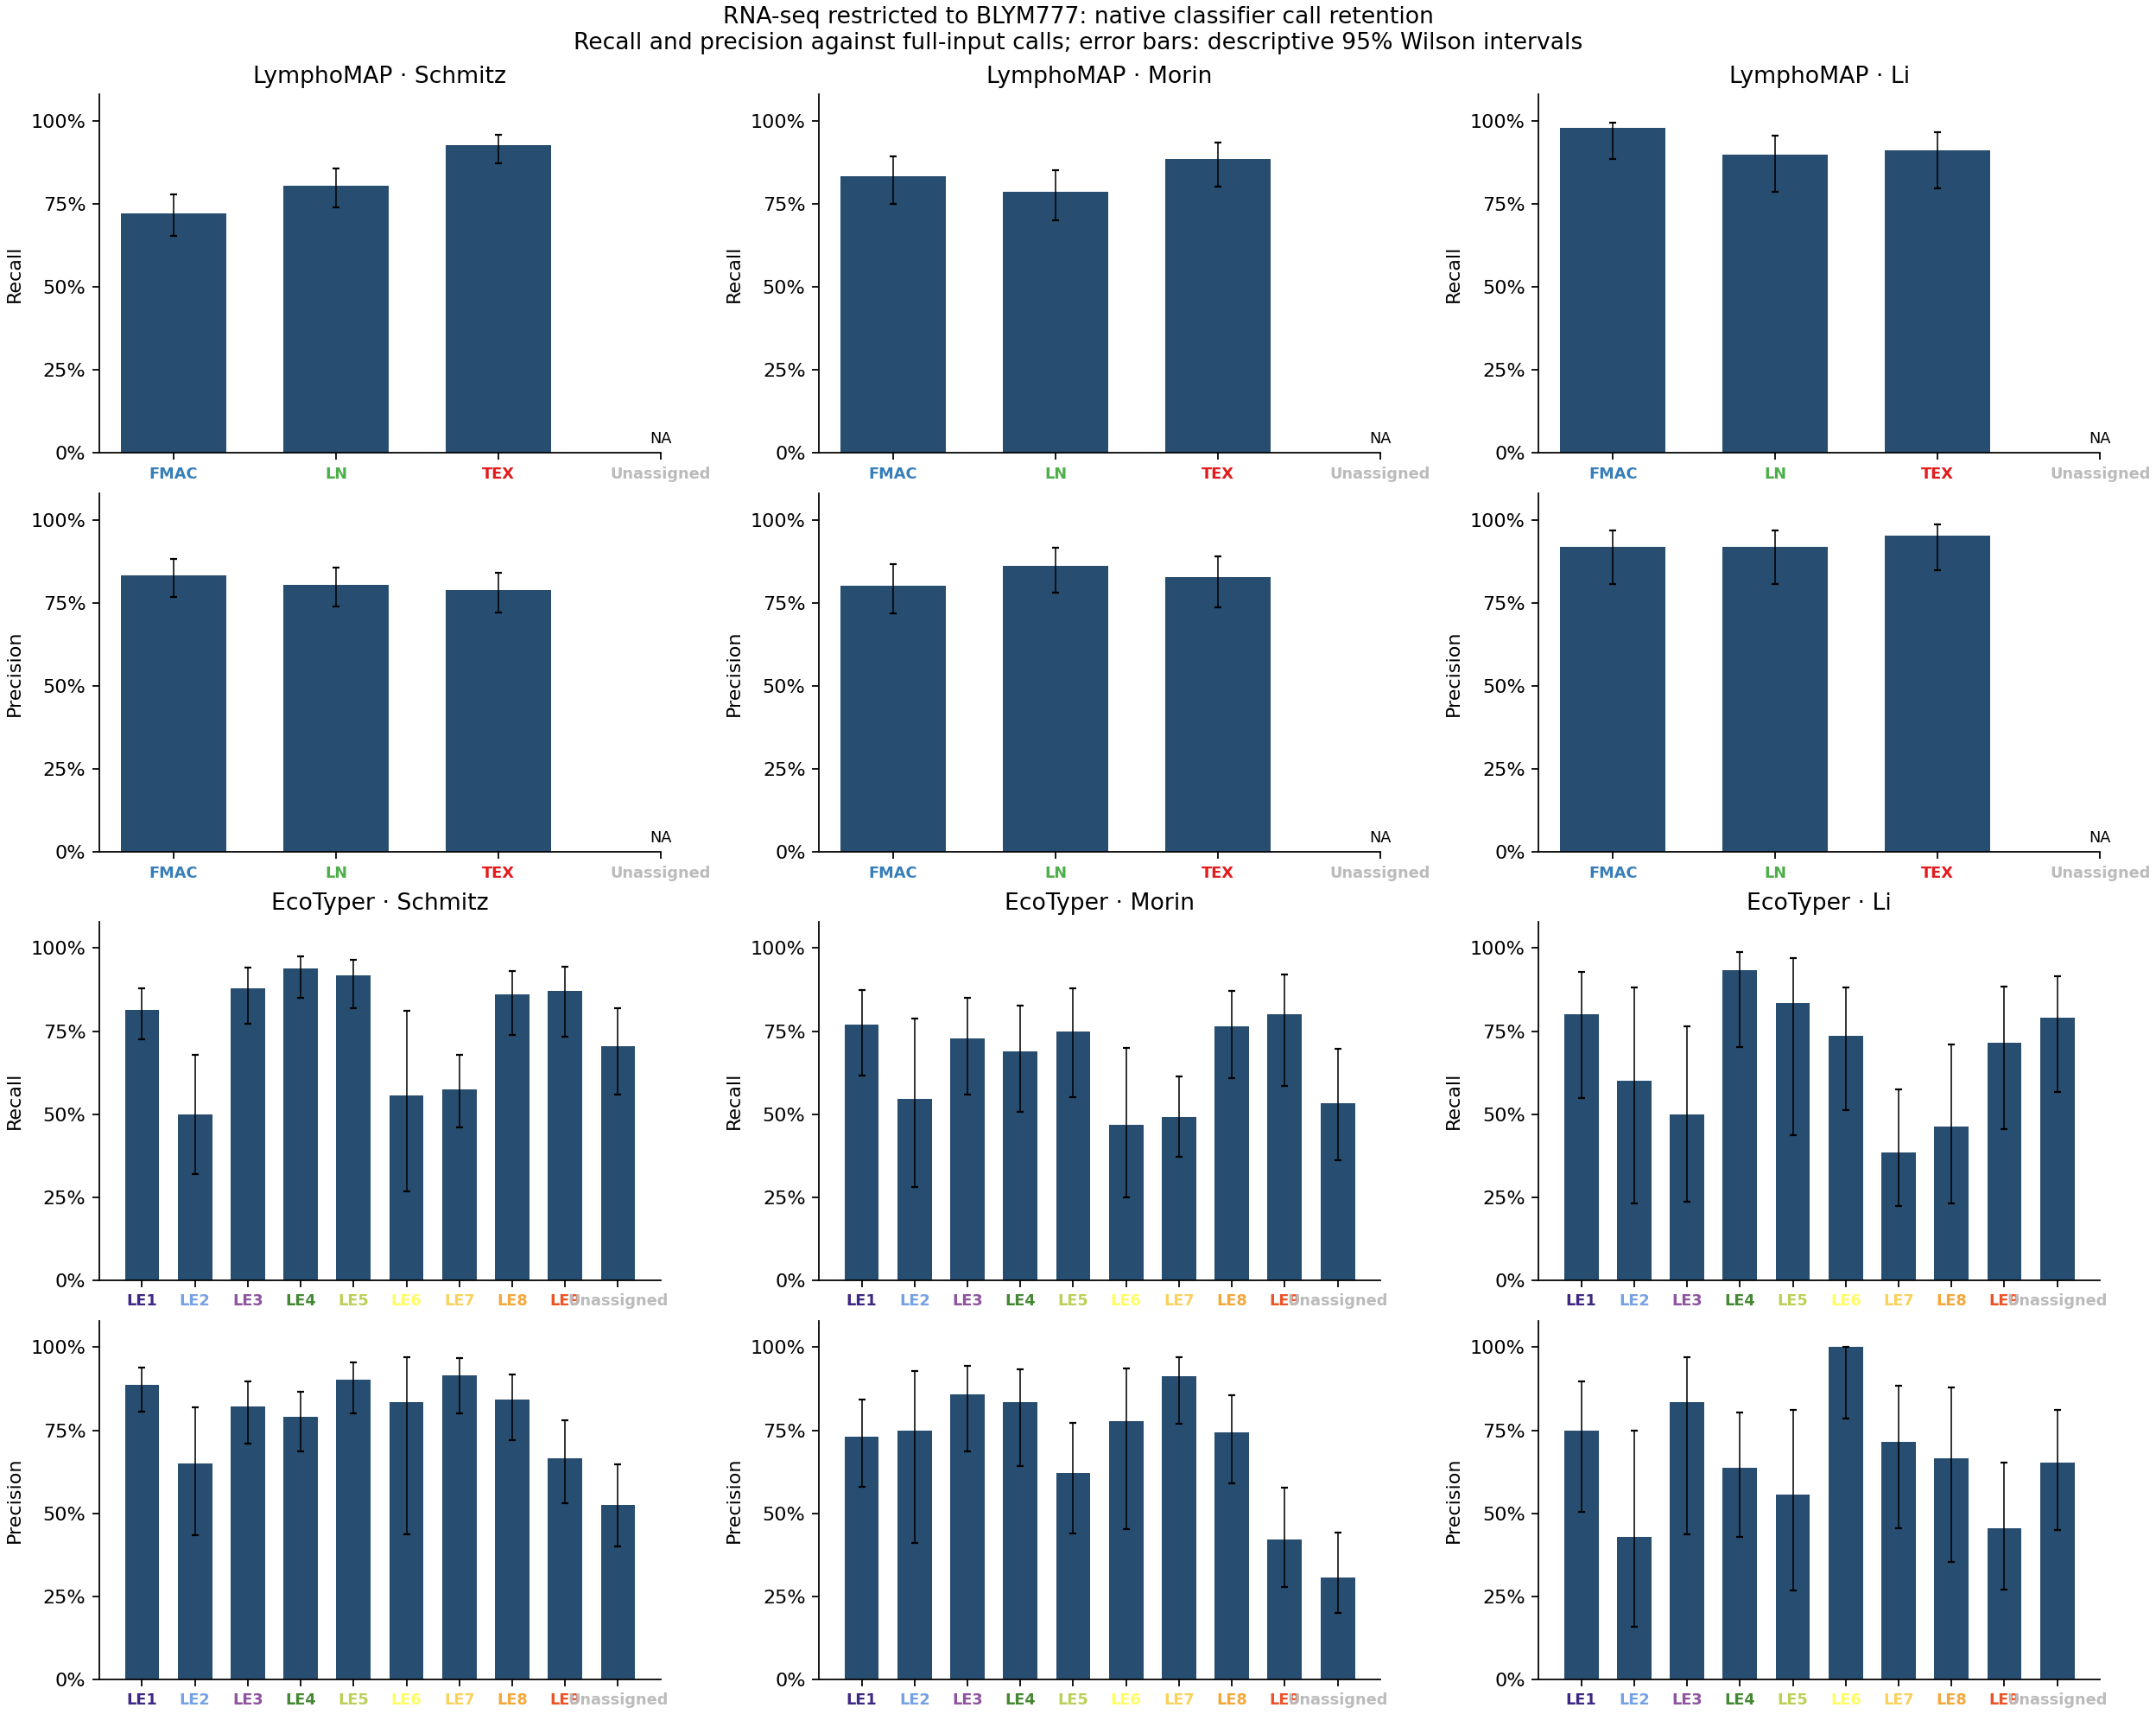

In [9]:
RNA_COHORTS = ['Schmitz', 'Morin', 'Li']
display(table(adata, 'transcriptomic', 'cohorts', 'Schmitz'))
counts = table(adata, 'transcriptomic', 'counts', 'Schmitz')
counts = counts[counts.group != 'Control']
counts = counts.groupby(['classifier','cohort','label'], observed=True, sort=False)[['tp','full_n','panel_n']].sum().reset_index()
metrics = metrics_from_counts(counts)
metrics.to_csv(OUT / 'native_classifier_metrics.csv', index=False)
show_save(plot_bars(metrics, ['LymphoMAP','EcoTyper'], RNA_COHORTS,
                   label_colors=LABEL_COLORS, title='RNA-seq restricted to BLYM777: native classifier call retention'), 'native_recall_precision')

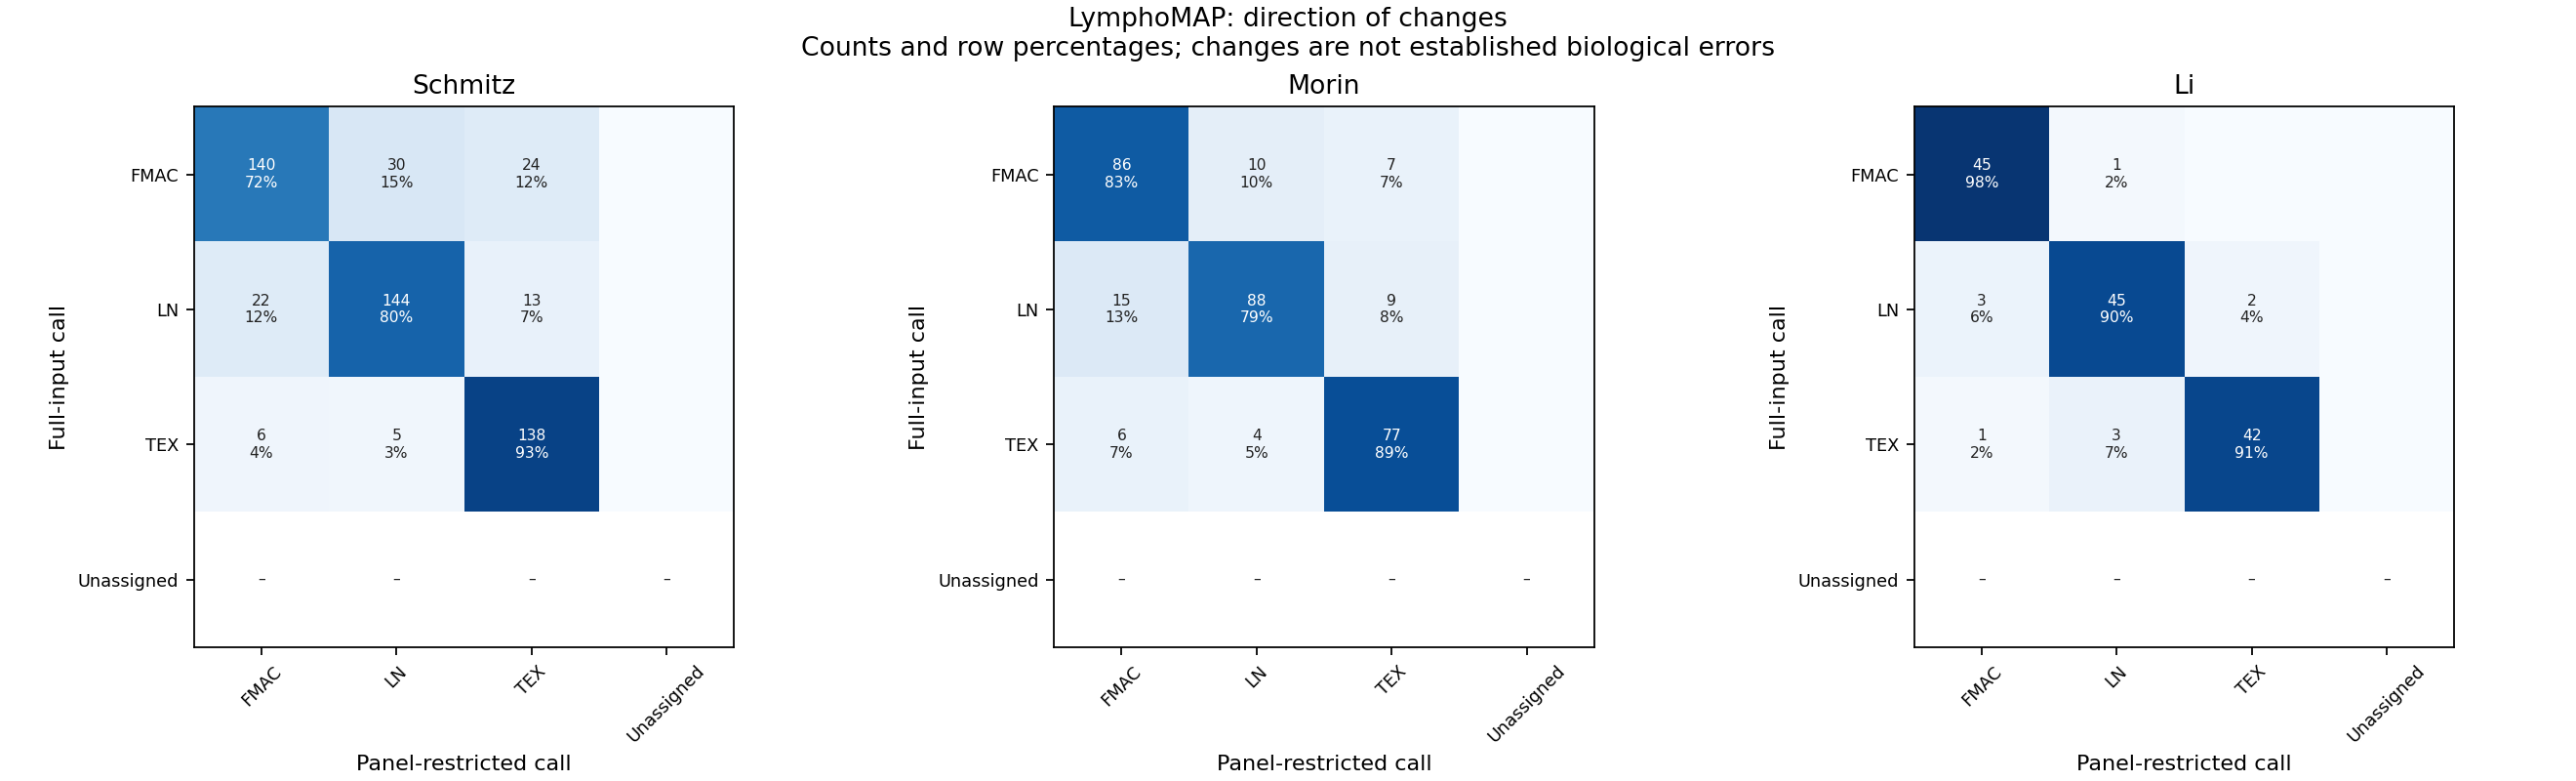

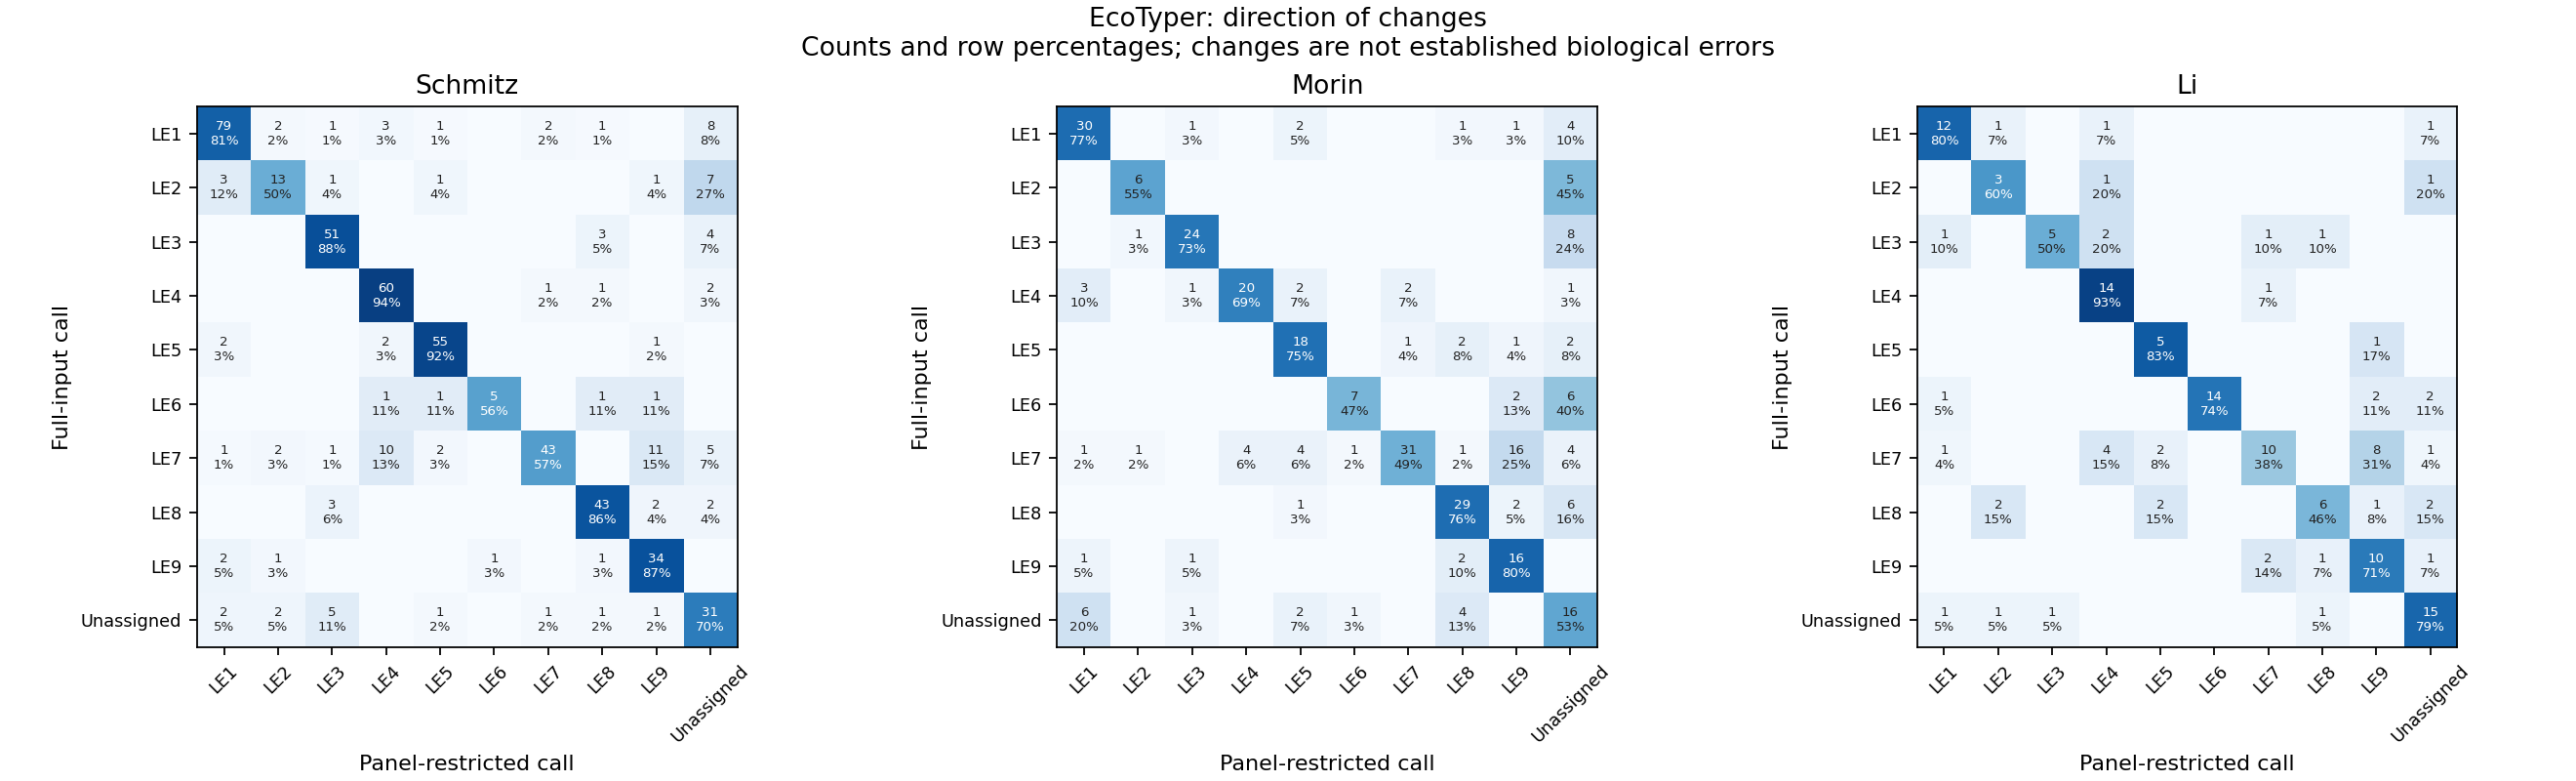

,classifier,cohort,group,n,matching_calls,agreement,agreement_low,agreement_high,full_assigned,panel_assigned,full_assigned_retained,retention_among_full_assigned
0,LymphoMAP,Schmitz,External RNA-seq,522,422,0.808429,0.772464,0.839887,522,522,422,0.808429
1,EcoTyper,Schmitz,External RNA-seq,522,414,0.793103,0.756273,0.825651,478,463,383,0.801255
2,LymphoMAP,Morin,External RNA-seq,302,251,0.831126,0.784774,0.869159,302,302,251,0.831126
3,EcoTyper,Morin,External RNA-seq,302,197,0.652318,0.596998,0.703812,272,250,181,0.665441
4,LymphoMAP,Li,Relapsed/refractory,64,61,0.953125,0.871003,0.983931,64,64,61,0.953125
5,LymphoMAP,Li,Control,11,11,1.000000,0.741167,1.000000,11,11,11,1.000000
6,LymphoMAP,Li,Newly diagnosed,78,71,0.910256,0.826153,0.955847,78,78,71,0.910256
7,EcoTyper,Li,Relapsed/refractory,64,43,0.671875,0.549991,0.774294,51,49,32,0.627451
8,EcoTyper,Li,Newly diagnosed,78,51,0.653846,0.543302,0.749948,72,70,47,0.652778
9,EcoTyper,Li,Control,11,6,0.545455,0.280092,0.787287,10,9,5,0.500000


In [10]:
transitions = table(adata, 'transcriptomic', 'transitions', 'Schmitz')
transitions = transitions[transitions.group != 'Control']
for classifier in ['LymphoMAP','EcoTyper']:
    show_save(plot_transitions(transitions, classifier, RNA_COHORTS), classifier.lower()+'_transitions')
display(table(adata, 'transcriptomic', 'overall', 'Schmitz'))

## Kotlov and Ciavarella: unsupervised cluster stability

These results assess reconstructed unsupervised workflows. Kotlov uses the original 25 signature/pathway scores and cohort-specific Louvain clustering, with graph thresholds selected separately in full and restricted runs. The threshold grid, ranking rule and current Louvain implementation are explicit reconstruction choices. Four clusters are not forced. Ciavarella uses Euclidean/Ward clustering of its 45-gene signature, cut to three groups.

Cluster recall and precision are calculated **after one-to-one maximum-overlap alignment**. This is descriptive membership retention, optimized on these samples, not predictive accuracy against independently supplied biological labels. Kotlov C1/C2/etc. are cohort-specific cluster IDs, not the published GC/ME/IN/DE subtypes. ARI and NMI assess partition similarity without matching names. All 45 Ciavarella targets are on-panel; 44 are available in Morin and all 45 in the other matrices. The same available genes enter each paired run, explaining perfect retention without establishing platform equivalence.

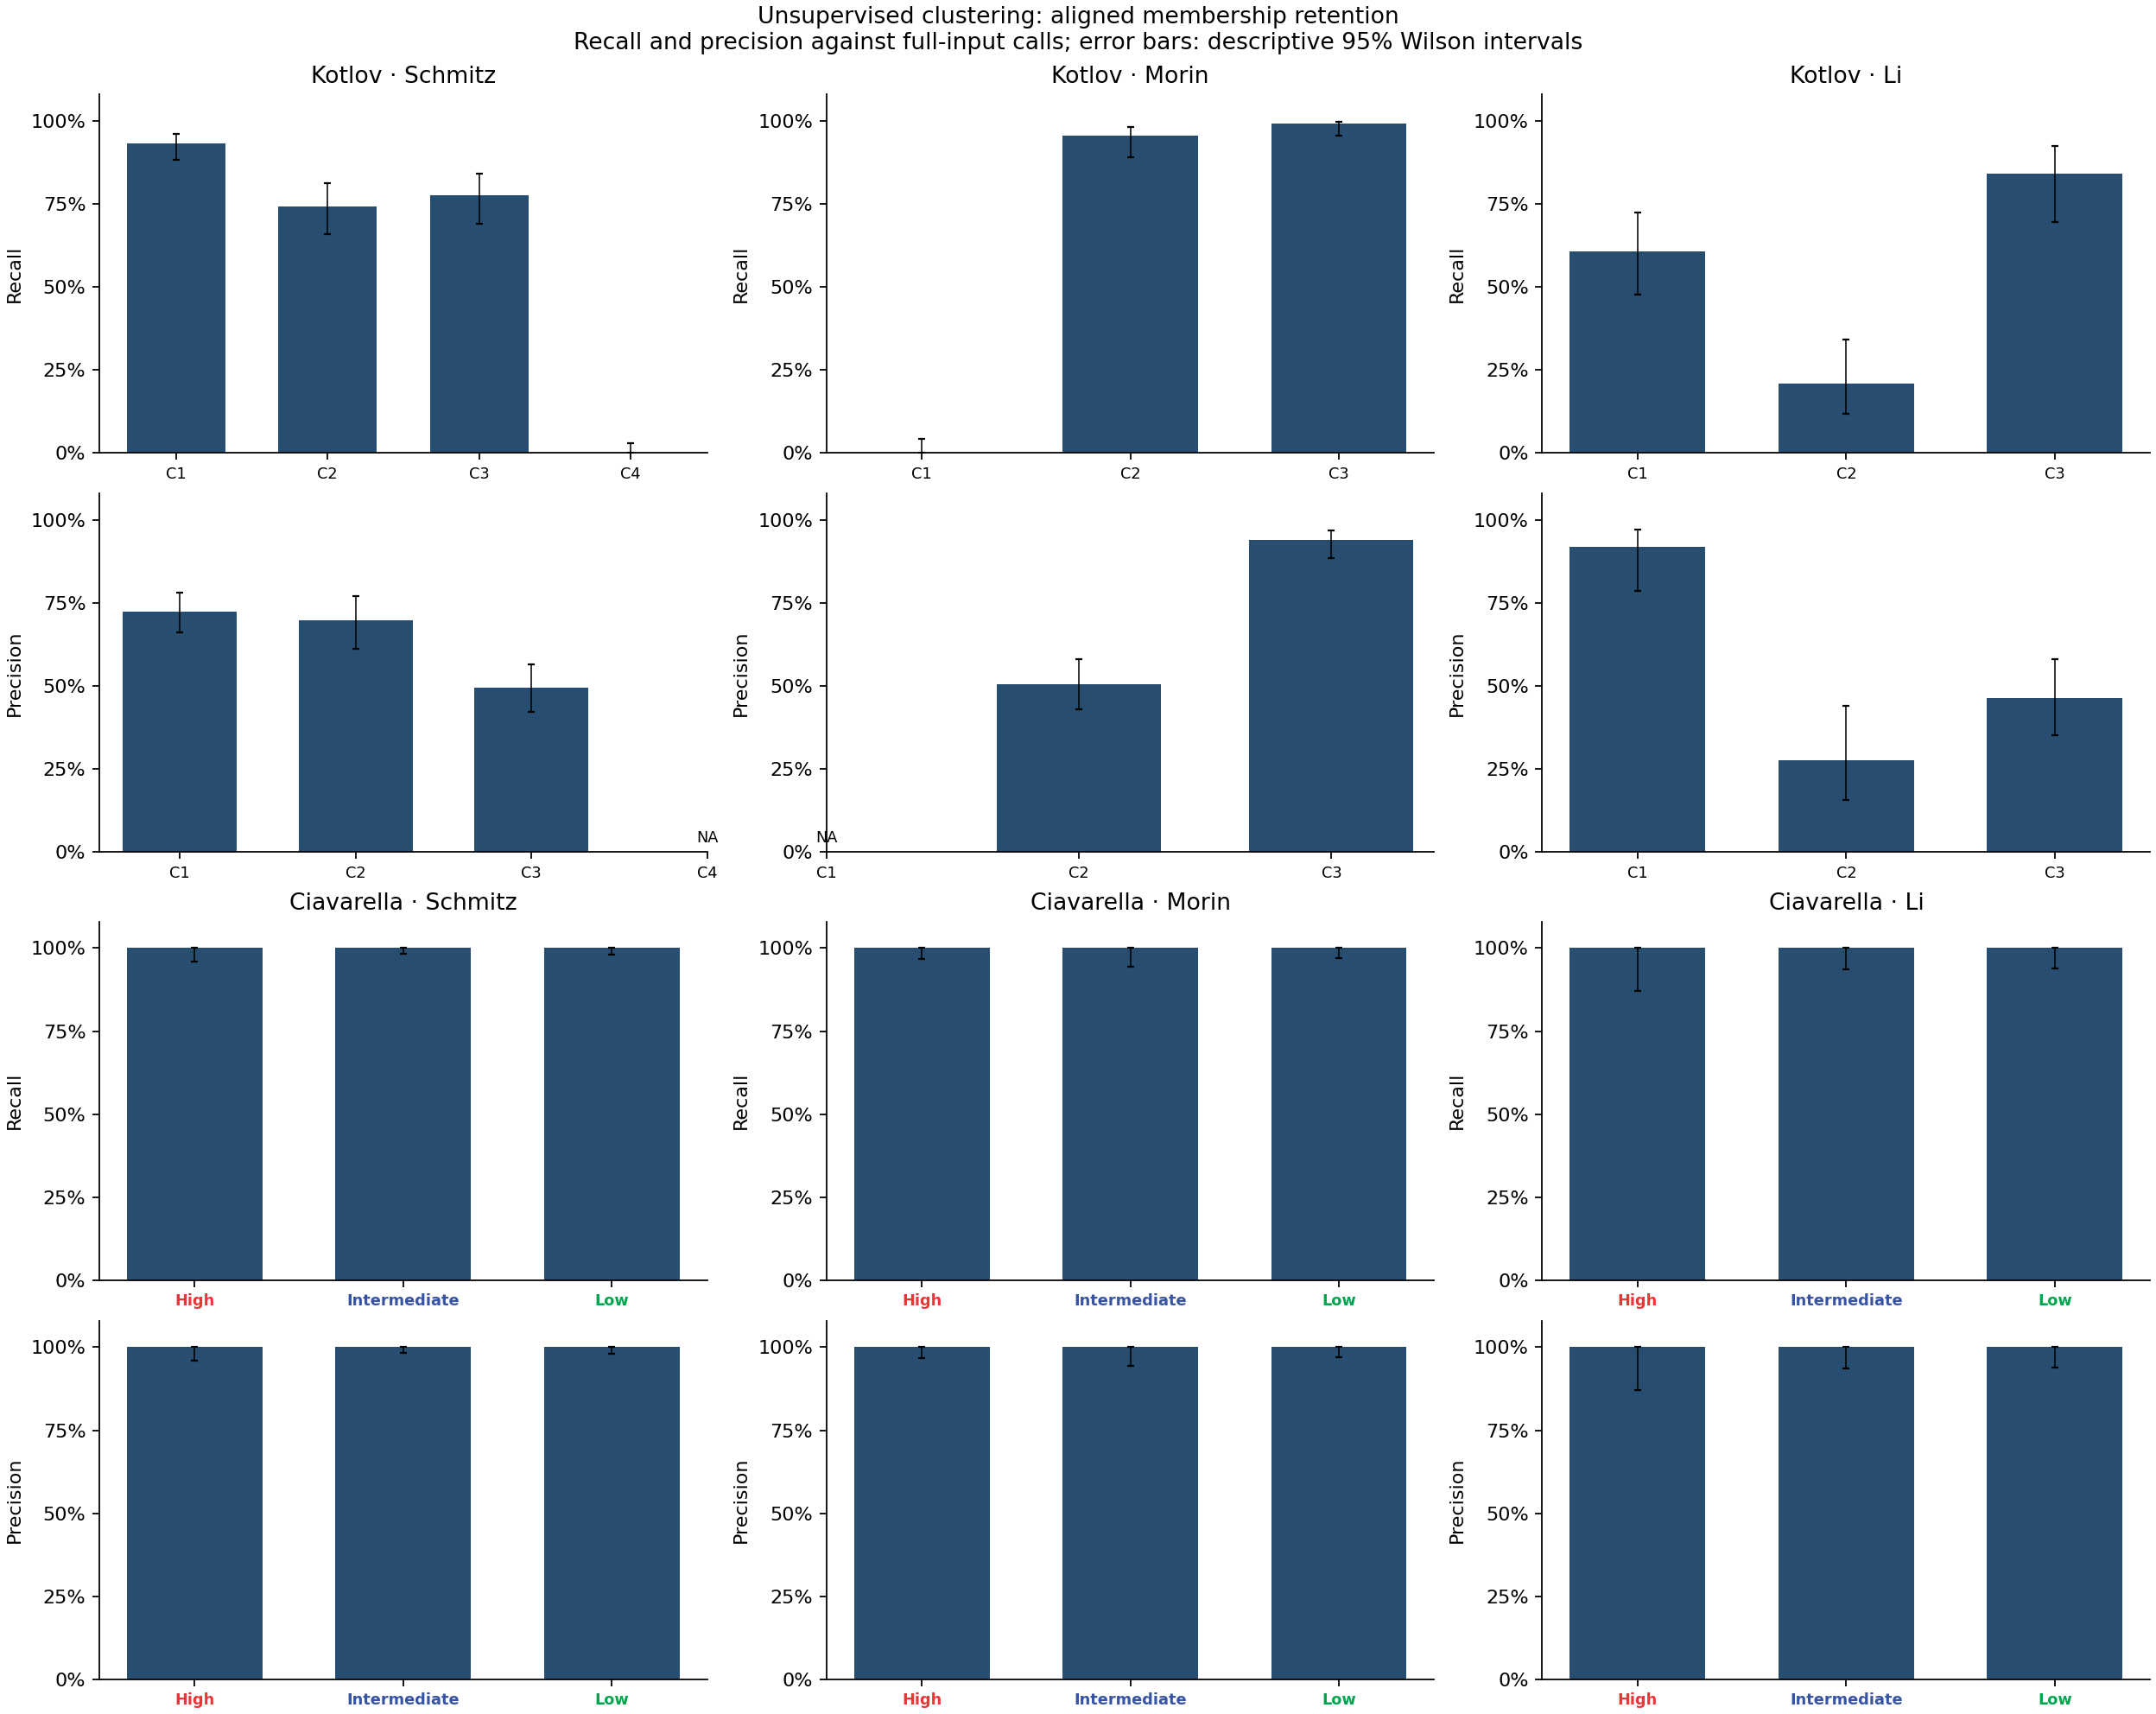

,classifier,cohort,comparison,full_threshold,panel_threshold,n,full_clusters,panel_clusters,adjusted_rand,normalized_mutual_information,aligned_agreement
0,Kotlov,Schmitz,independently_selected,0.10,0.00,522,4,3,0.408717,0.400399,0.637931
1,Kotlov,Schmitz,full_threshold_locked,0.10,0.10,522,4,3,0.223283,0.289155,0.482759
2,Ciavarella,Schmitz,log_expression,NaN,NaN,522,3,3,1.000000,1.000000,1.000000
3,Ciavarella,Schmitz,gene_zscore,NaN,NaN,522,3,3,1.000000,1.000000,1.000000
4,Kotlov,Morin,independently_selected,0.30,0.00,302,3,2,0.607111,0.633023,0.698675
5,Kotlov,Morin,full_threshold_locked,0.30,0.30,302,3,3,0.624478,0.598266,0.791391
6,Ciavarella,Morin,log_expression,NaN,NaN,302,3,3,1.000000,1.000000,1.000000
7,Ciavarella,Morin,gene_zscore,NaN,NaN,302,3,3,1.000000,1.000000,1.000000
8,Kotlov,Li,independently_selected,0.15,0.10,142,3,3,0.298067,0.350287,0.535211
9,Kotlov,Li,full_threshold_locked,0.15,0.15,142,3,3,0.298067,0.350287,0.535211


In [11]:
cluster_counts = table(adata, 'transcriptomic', 'cluster_counts', 'Schmitz')
cluster_metrics = metrics_from_counts(cluster_counts)
cluster_metrics.to_csv(OUT / 'cluster_retention_metrics.csv', index=False)
show_save(plot_bars(cluster_metrics, ['Kotlov','Ciavarella'], RNA_COHORTS,
                   label_colors=LABEL_COLORS, title='Unsupervised clustering: aligned membership retention'), 'clustering_recall_precision')
display(table(adata, 'transcriptomic', 'cluster_summary', 'Schmitz'))

## Chapuy: separate microarray sensitivity

These 135 samples are not pooled with RNA-seq. LymphoMAP uses its native microarray input mode. The remaining comparisons use the supplied paired log-expression inputs. Retention here does not validate cross-platform measurements.

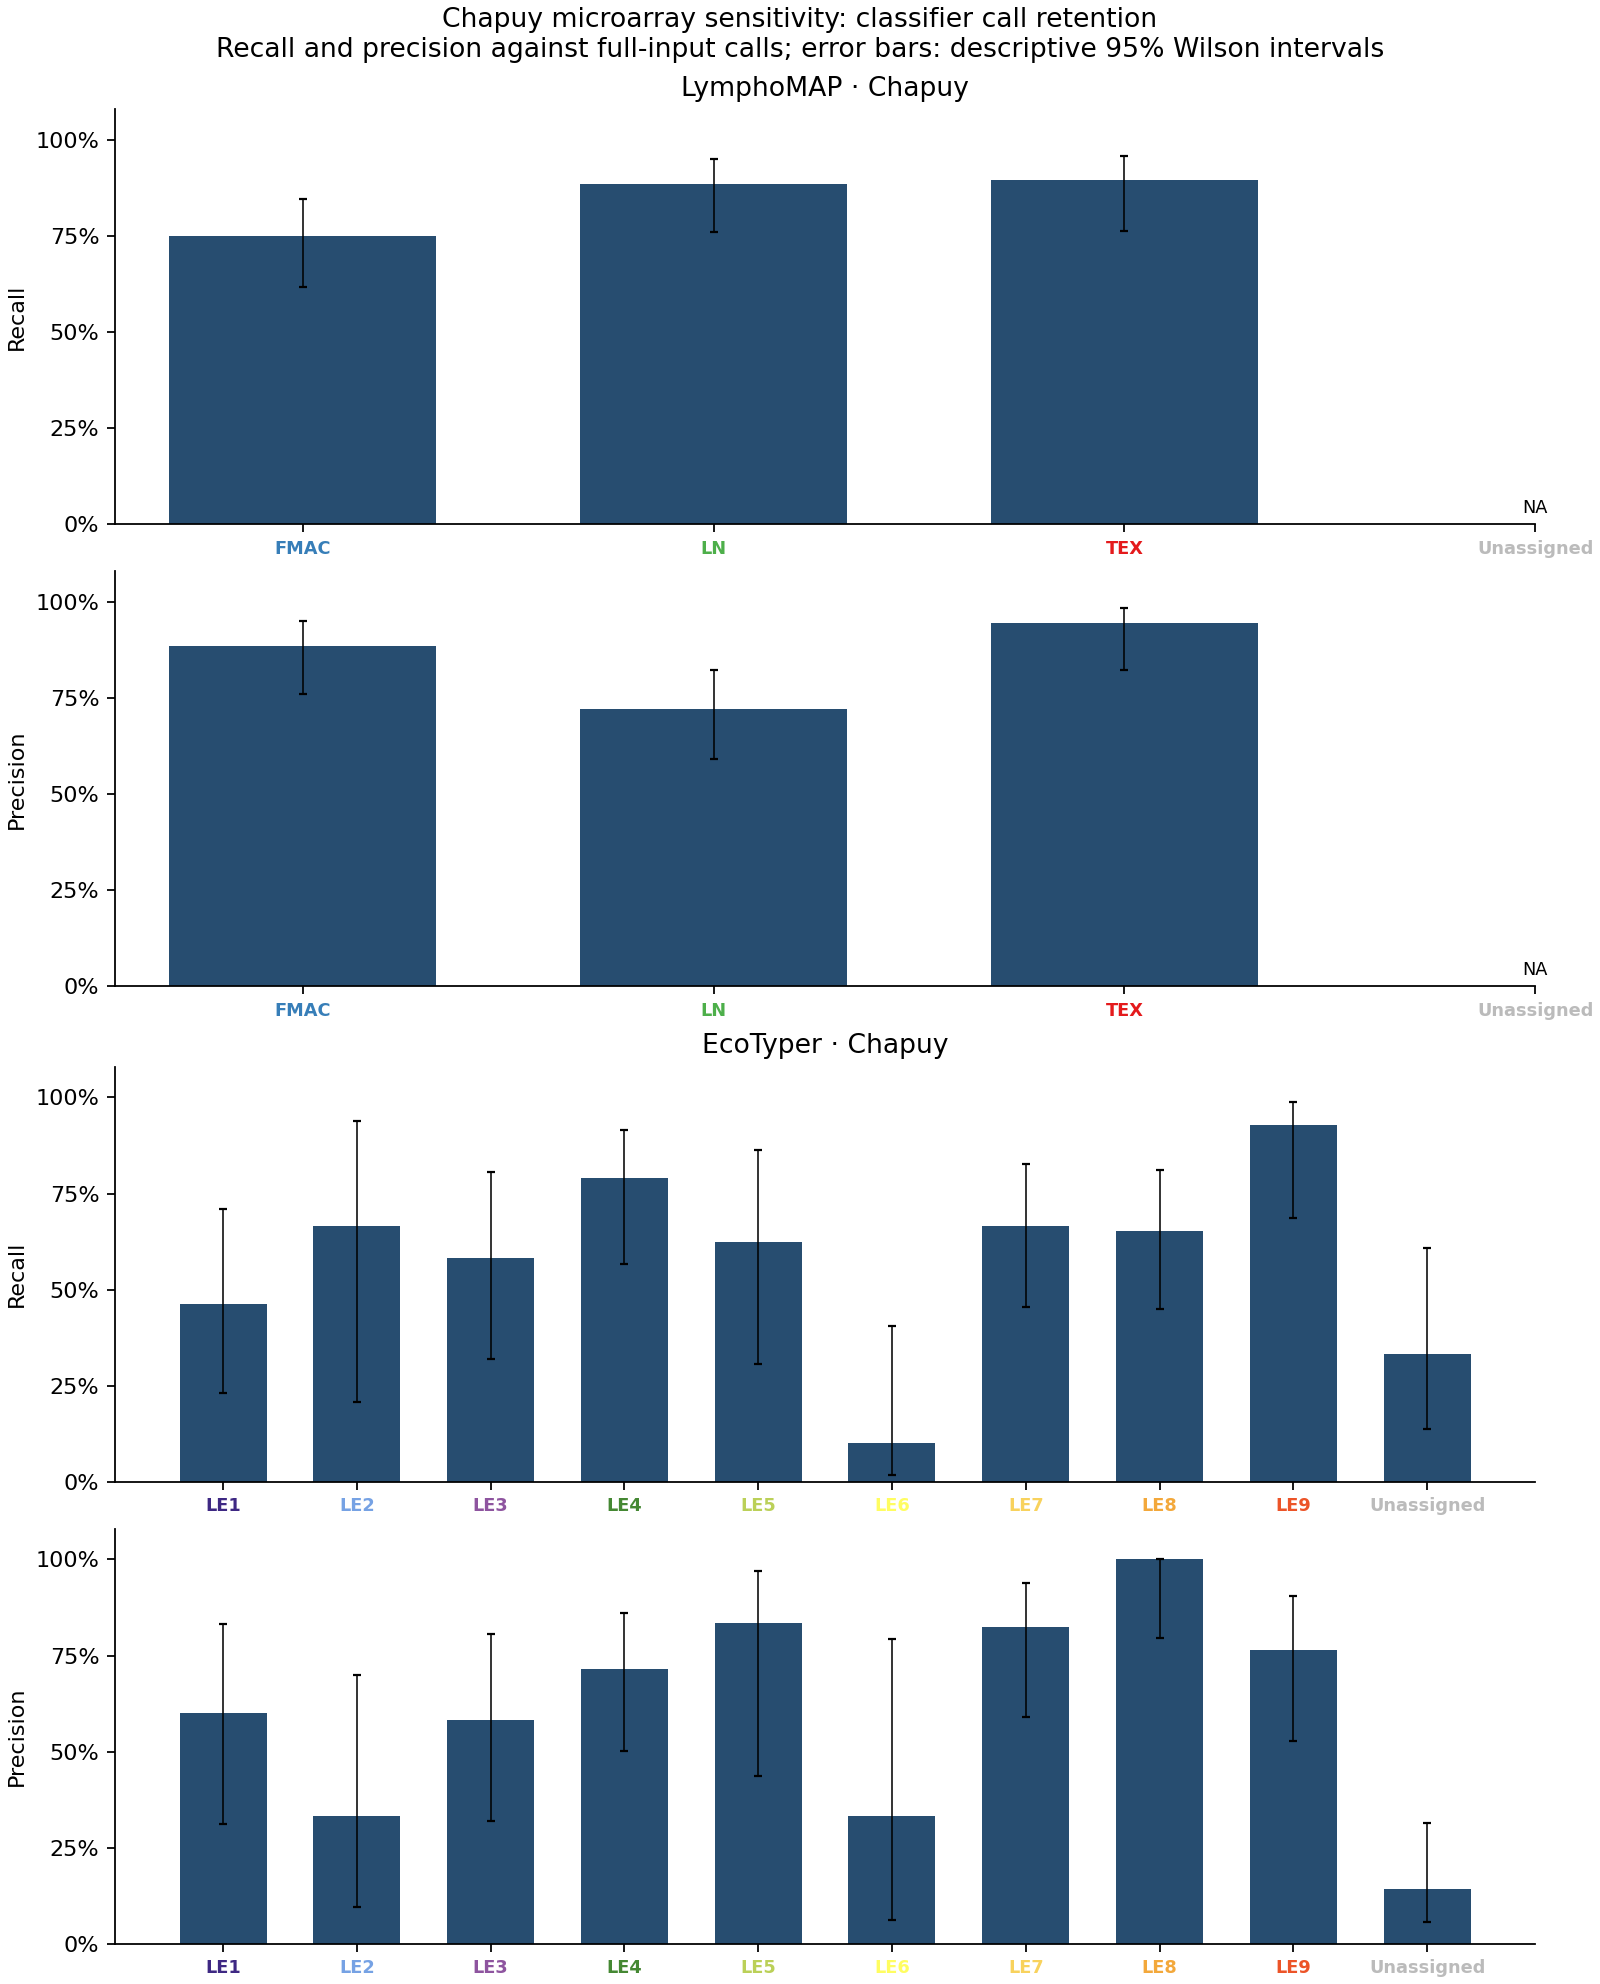

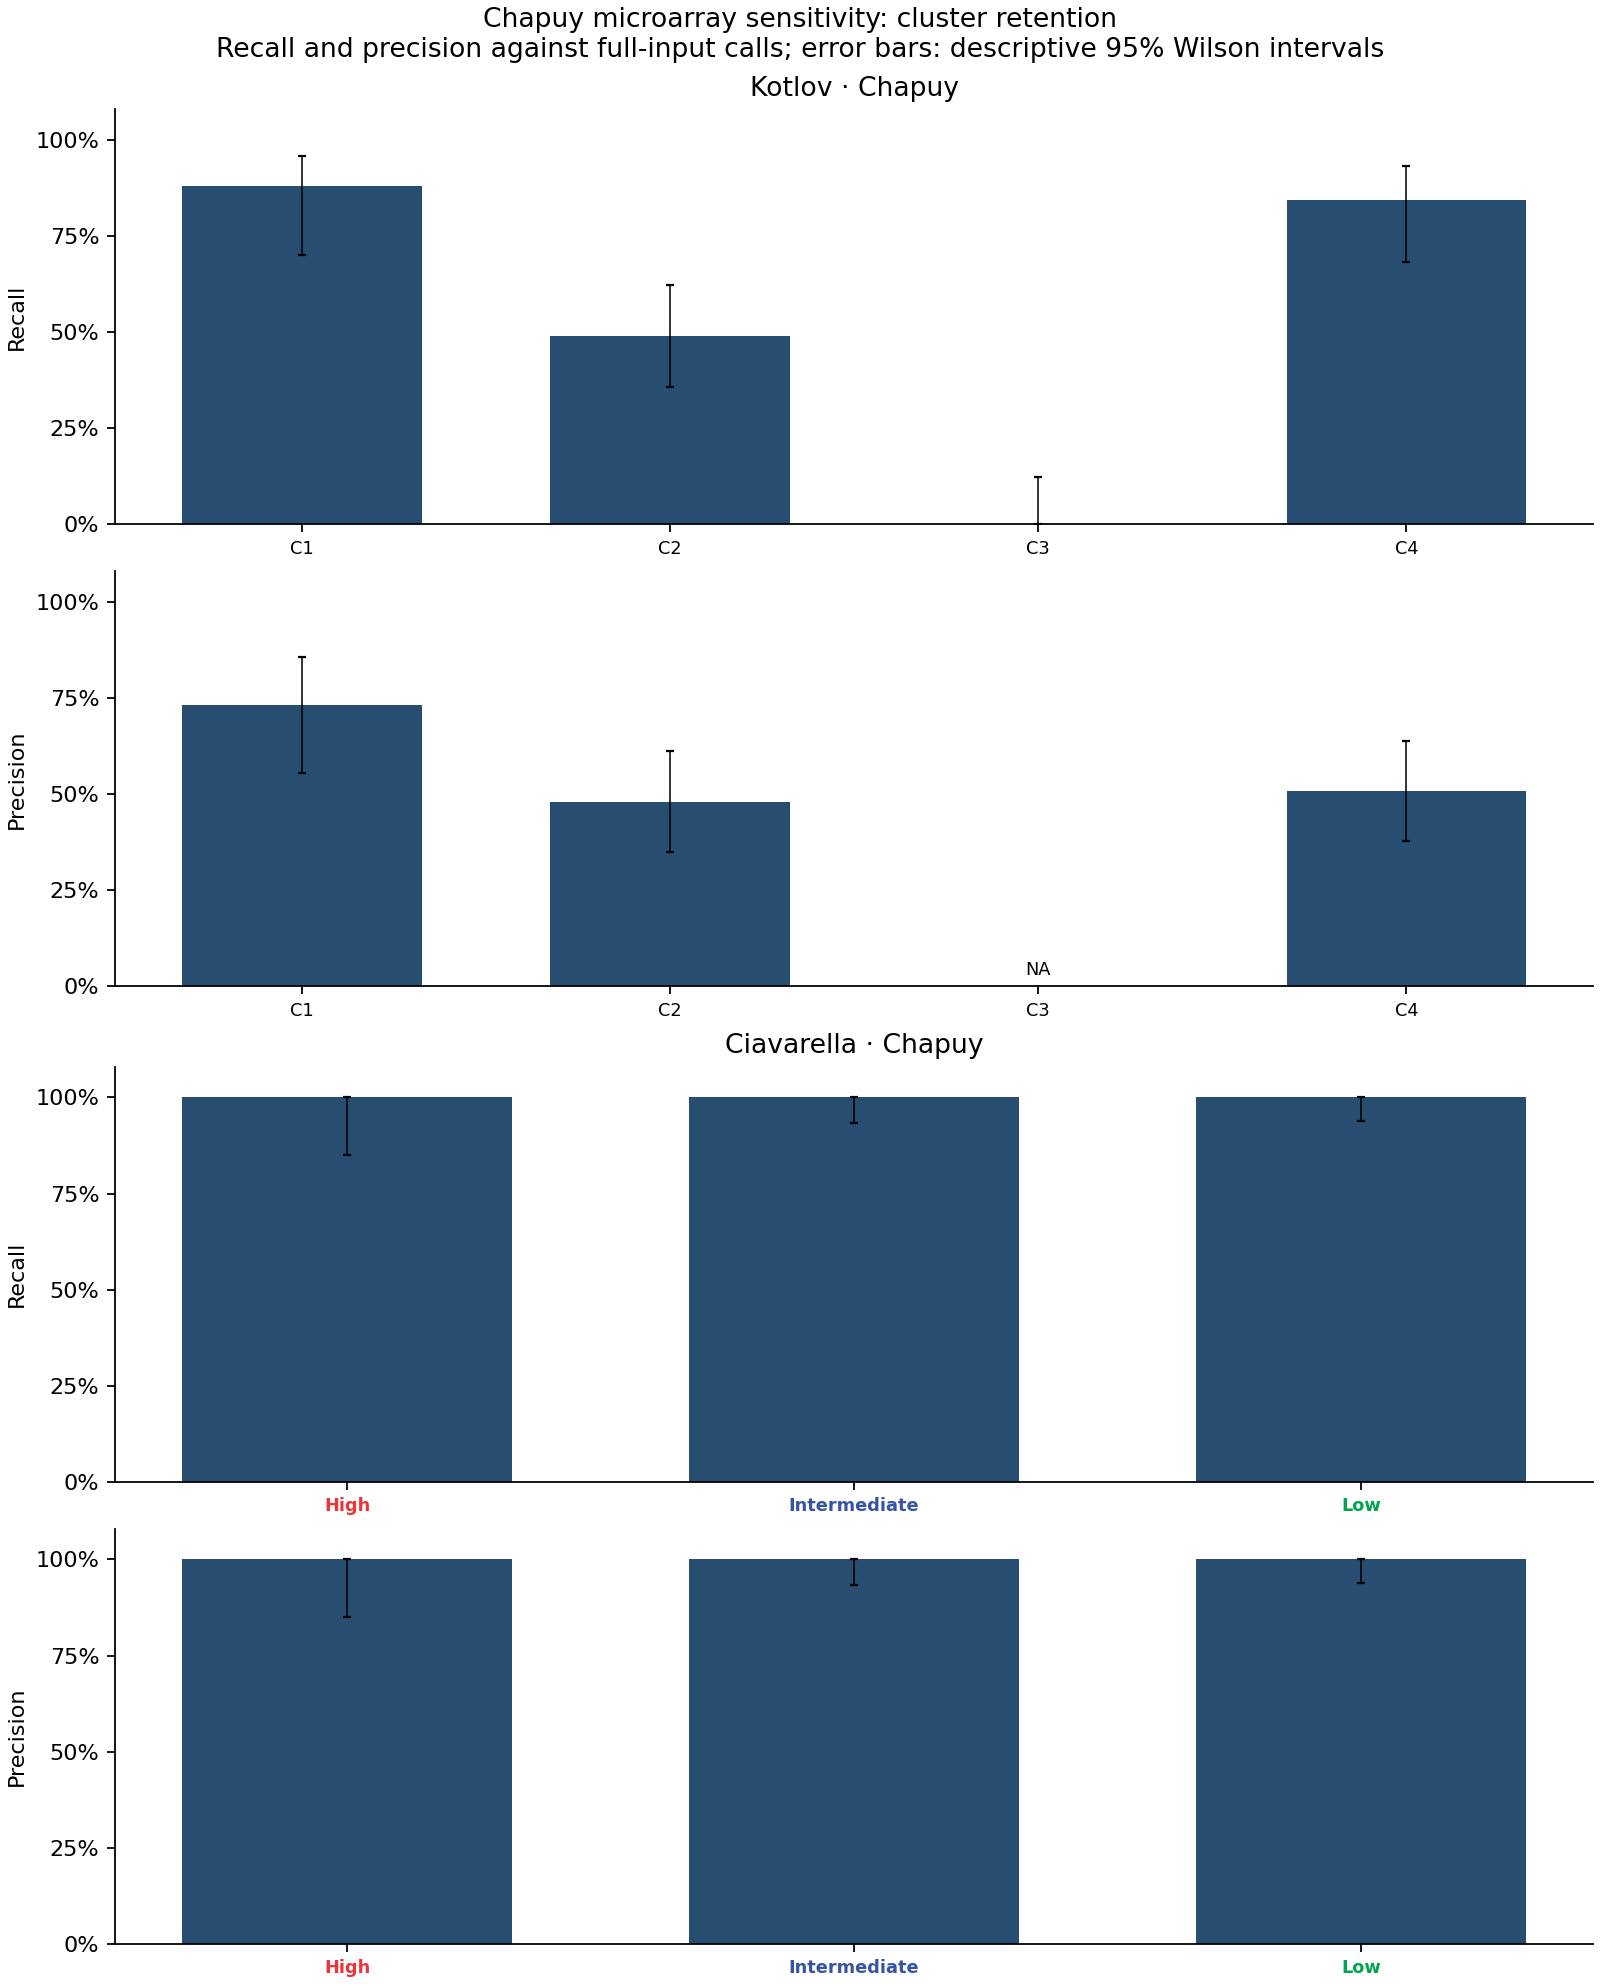

In [12]:
show_save(plot_bars(metrics, ['LymphoMAP','EcoTyper'], ['Chapuy'],
                   label_colors=LABEL_COLORS, title='Chapuy microarray sensitivity: classifier call retention'), 'chapuy_native')
show_save(plot_bars(cluster_metrics, ['Kotlov','Ciavarella'], ['Chapuy'],
                   label_colors=LABEL_COLORS, title='Chapuy microarray sensitivity: cluster retention'), 'chapuy_clustering')

## Agreement with available published annotations

This is a separate comparison of full-input calls with supplied external annotations. Li is training-overlapping data. Schmitz EcoTyper discovery labels need not equal bulk-recovery calls. The generic COO labels in Schmitz, Li and Chapuy are not relabelled as Lymph2Cx assay truth.

In [13]:
display(table(adata, 'transcriptomic', 'reference_summary', 'Li'))
display(table(adata, 'transcriptomic', 'reference_metrics', 'Li'))

,cohort,classifier,group,n,matching_calls,agreement
0,Li,LymphoMAP,Tumors,142,140,0.985915
1,Li,LymphoMAP,Control,11,11,1.000000
2,Li,EcoTyper,Tumors,142,124,0.873239
3,Li,EcoTyper,Control,11,11,1.000000
4,Schmitz,EcoTyper,External RNA-seq,522,436,0.835249


,cohort,classifier,group,label,reference_n,full_n,matching_calls,recall,precision
0,Li,LymphoMAP,Tumors,FMAC,47,46,46,0.978723,1.000000
1,Li,LymphoMAP,Tumors,LN,50,50,49,0.980000,0.980000
2,Li,LymphoMAP,Tumors,TEX,45,46,45,1.000000,0.978261
3,Li,LymphoMAP,Control,FMAC,5,5,5,1.000000,1.000000
4,Li,LymphoMAP,Control,LN,6,6,6,1.000000,1.000000
5,Li,EcoTyper,Tumors,LE1,19,15,14,0.736842,0.933333
6,Li,EcoTyper,Tumors,LE2,5,5,5,1.000000,1.000000
7,Li,EcoTyper,Tumors,LE3,8,10,7,0.875000,0.700000
8,Li,EcoTyper,Tumors,LE4,16,15,15,0.937500,1.000000
9,Li,EcoTyper,Tumors,LE5,9,6,6,0.666667,1.000000


## Full Lymph2Cx: public external NanoString calibration

GSE178394 contains 170 cases with explicit assay labels (80 GCB, 31 UNC, 59 ABC), all **15 predictor genes and five housekeeping genes**, and positive raw counts. The complete public-patent weights are fixed; no predictor is omitted or imputed. RAB7L1 is mapped to RAB29, and ISY1 is measured directly. Scores use log2 counts minus the five-housekeeping-gene mean.

The notebook recomputes five-fold stratified evaluation, fitting only the two boundaries within each training fold. Every case is evaluated once outside its calibration fold. The editable borders below affect the fixed-boundary calls and score plot, **not the held-out benchmark**. At default all-external-fit borders, fixed-boundary agreement is resubstitution. This is a research reconstruction; reference-probe correction, posterior probabilities and full portal QC are not reproduced.

All 20 genes are BLYM777 targets, so panel restriction does not change these inputs. The RNA-seq coverage table separately exposes genes absent from a source matrix; such absence is not silently imputed. The full 20-gene model is evaluated on GSE178394, where every required input is present.

Sources: [GSE178394](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE178394), [Scott et al., Lymph2Cx](https://doi.org/10.1182/blood-2013-11-536433), [public coefficients, Table 6](https://patents.google.com/patent/WO2015069790A1/en).

Held-out agreement: 167/170 (98.2%)


,label,full_n,panel_n,tp,recall,precision
0,GCB,80,78,78,0.975000,1.000000
1,UNC,31,34,31,1.000000,0.911765
2,ABC,59,58,58,0.983051,1.000000


,fold,training_n,test_n,lower,upper
0,1,136,34,715.465319,1248.436350
1,2,136,34,716.851915,1249.575718
2,3,136,34,715.465319,1249.575718
3,4,136,34,697.467392,1263.782133
4,5,136,34,715.465319,1249.575718


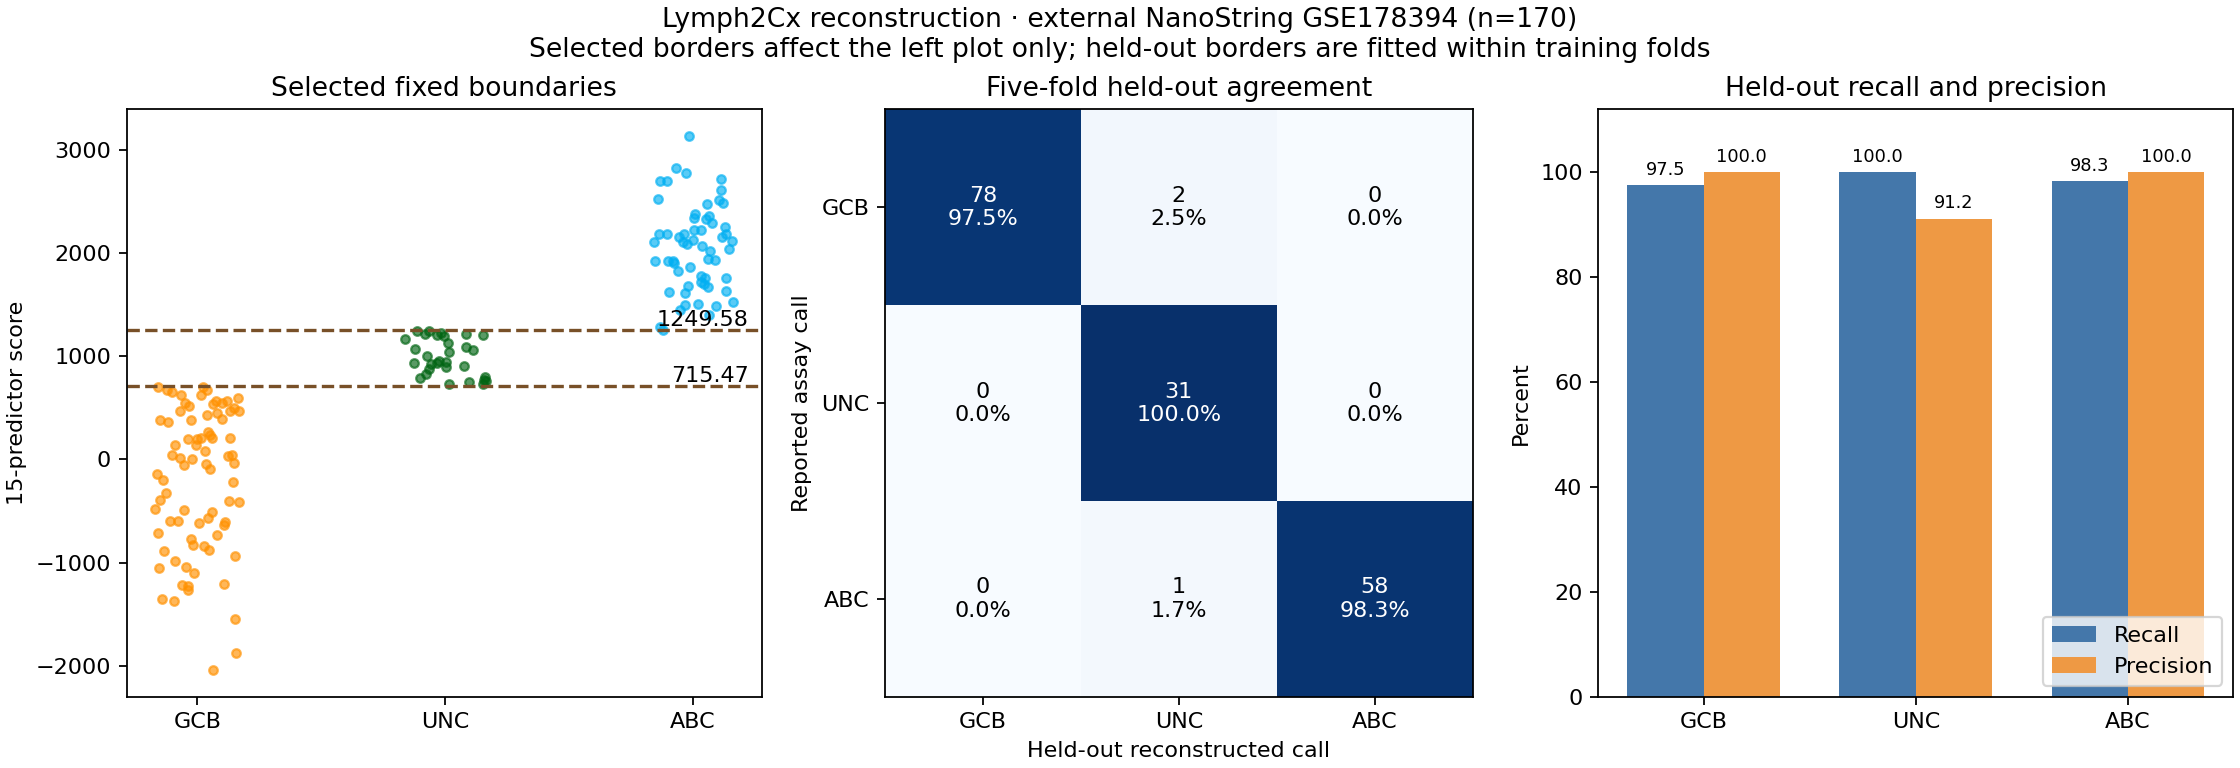

,cohort,platform,n,signature_genes,panel_genes,genes_available_in_source,missing_source_genes,identical_available_inputs
0,Schmitz,RNA-seq,522,20,20,20,,True
1,Morin,RNA-seq,302,20,20,18,ISY1;RAB29,True
2,Li,RNA-seq,153,20,20,20,,True
3,Chapuy,microarray,135,20,20,20,,True


In [14]:
# Explicit hyperparameters for fixed-boundary calls. Held-out fitting stays independent.
GCB_UNC_THRESHOLD = 715.4653189529806
UNC_ABC_THRESHOLD = 1249.575718489061
CV_SEED = 20261016
from dlbcl.public_panel_confidence import lymph2cx_external, plot_lymph2cx
coo, coo_metrics, folds = lymph2cx_external(
    adata, GCB_UNC_THRESHOLD, UNC_ABC_THRESHOLD, seed=CV_SEED)
targets = set(table(adata, 'transcriptomic', 'targets', 'Li').gene)
assert set(require_source(adata, 'GSE178394').columns) <= targets
matches = int(coo.reference_label.eq(coo.held_out_call).sum())
print(f'Held-out agreement: {matches}/{len(coo)} ({matches/len(coo):.1%})')
display(coo_metrics[['label','full_n','panel_n','tp','recall','precision']])
display(folds)
show_save(plot_lymph2cx(coo, coo_metrics, GCB_UNC_THRESHOLD, UNC_ABC_THRESHOLD, colors=LABEL_COLORS['Lymph2Cx']), 'lymph2cx_external')
coo.to_csv(OUT / 'lymph2cx_external_calls.csv')
folds.to_csv(OUT / 'lymph2cx_training_fold_boundaries.csv', index=False)
display(table(adata, 'transcriptomic', 'lymph2cx_coverage', 'Morin'))

## Source data availability

The default figures regenerate metrics from **released aggregate external benchmark counts**. Full model inference for LymphGen, DLBclass, LymphoMAP, EcoTyper, Kotlov and Ciavarella is not rerun by these plotting cells. Their reference cohorts and methods are documented above. The transcriptomic notebook does recompute the full Lymph2Cx model and cross-validation from the included public NanoString counts.

The source inventory distinguishes publicly included matrices, publicly available upstream datasets not bundled here, and exact source matrices not redistributed. A missing source is never silently replaced. Requesting a nonredistributed source raises `SourceDataUnavailableError`: **“The source data cannot be released with this public AnnData bundle”**, followed by the relevant paper and access route. Public datasets missing from the bundle instead get a public-download message; absence does not imply that the original dataset is legally restricted.

To inspect a source, set `SOURCE_TO_LOAD` below. Leaving it `None` generates figures from the bundled benchmark tables.

In [15]:
SOURCE_TO_LOAD = None  # Choose one of ['Schmitz', 'Morin', 'Li', 'Chapuy', 'GSE178394'] to load its original source matrix.
inventory = pd.DataFrame.from_dict(SOURCES, orient='index').loc[['Schmitz', 'Morin', 'Li', 'Chapuy', 'GSE178394']]
display(inventory[['paper', 'citation', 'status', 'access', 'note']])
if SOURCE_TO_LOAD is not None:
    source_matrix = require_source(adata, SOURCE_TO_LOAD)  # Deliberate hard error if unavailable.
    display(source_matrix.iloc[:5, :5])


,paper,citation,status,access,note
Schmitz,"Schmitz et al., NEJM 2018, Genetics and Pathog...",https://doi.org/10.1056/NEJMoa1801445,source_not_bundled,https://gdc.cancer.gov/about-data/publications...,Harmonized expression matrix used in this benc...
Morin,"Ennishi et al., JCO 2019, Double-Hit Gene Expr...",https://doi.org/10.1200/JCO.18.01583,source_not_bundled,https://pmc.ncbi.nlm.nih.gov/articles/PMC8178179/,Expression matrix used in this benchmark is no...
Li,"Li et al., Cancer Cell 2025, Large B cell lymp...",https://pmc.ncbi.nlm.nih.gov/articles/PMC12417...,public_upstream_not_bundled,https://github.com/Green-Lab-MDACC/LymphoMapR/...,Author training data are publicly distributed ...
Chapuy,"Chapuy et al., Nature Medicine 2018, Molecular...",https://doi.org/10.1038/s41591-018-0016-8,public_upstream_not_bundled,https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi...,Public microarray deposit; exact preprocessing...
GSE178394,"Miyawaki and Sugio, GSE178394: NanoString prof...",https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi...,public_matrix_included,https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi...,All 20 Lymph2Cx genes and 170 published assay ...


In [16]:
print('Figures and tables:', OUT.relative_to(ROOT))
display(json.loads(adata.uns['provenance_json']))

Figures and tables: figures/transcriptomic_panel_call_confidence


{'scope': 'External reference data and aggregate derived benchmarks only',
 'expression_sources_included': ['GSE178394: 20 measured classifier genes'],
 'genomic_sources_included': ['DLBclass: author-public 699-case encoded feature matrix'],
 'study_data_included': False,
 'raw_inference': 'Only Lymph2Cx is recomputed in these notebooks; other figures use archived external benchmark counts',
 'external_cohorts': ['Schmitz', 'Morin', 'Li', 'Chapuy', 'GSE178394'],
 'source_sha256': {'aligned_metrics.csv': '3f090340bac6708d859cec4b44c898f605b0a3239fcbd982ec94a8c8ad32a67c',
  'reference_pairs.csv': 'ba517f59af9d336bb9276ccc1616fdf6f4641533c1434b1baff65113048aca20',
  'overall_agreement.csv': '7a31753df6acbf9a7e3324c547a511122be40cac3b86dc8818b77dacc1e66350',
  'per_subtype_metrics.csv': '0dfe6a28af9749c5c32a952988c3ab4e29e762184f3e18860ddb1323a8379e27',
  'directional_transitions.csv': 'd9e5389bf16239483cb30e5930459f17d2f742addd9eb6db9655756e34de3fb7',
  'clustering_per_label_metrics.csv':